# Does resistance make recovery better—and more reliable?

A self-contained comparison of the **original deterministic consumer-resource model** with a **Gillespie-inspired stochastic extension**, using the same 57 intrinsic strain traits.

**Run:** Download, open in Jupyter, and choose **Restart Kernel → Run All**. Requires NumPy ≥1.20, pandas, SciPy, Matplotlib ≥3.7 and IPython. No additional model files needed. The executed figures are already included. First execution runs 10 resistance-assignment orders × 6 intermediate carrier counts × 10 random-event repeats × 2 treatment arms, plus shared zero/all-carrier references: **1,240 stochastic trajectories**, and deterministic comparisons. Cached matching simulations are reused on later runs.

## What varies, and what stays fixed?

- **Fixed:** 57 strain identities, intrinsic growth and IC50 traits, total inoculum, initial nutrient, resistance cost, antibiotic dose, degradation parameters, and treatment schedule. The original 10⁹ cells per OD is retained; noise is not artificially amplified.
- **Carrier count:** 0, 1, 5, 10, 20, 30, 40 or 57 strains. More carriers also means more initial resistant biomass; this does not isolate distribution at fixed resistant biomass.
- **Assignment order (10):** different choices of which strains carry resistance; sets are nested within each order. Trait seed is unchanged.
- **Event repeat (10 per assignment):** the *same* assignment and inoculum, but different random births and deaths. This is separate from changing carrier identities.
- **Treatment arm:** antibiotic-treated and a matching untreated configuration. Event repeats in the two arms use independent random streams; repeat indices pair them for reporting, not as common-noise controls.

The 0- and 57-carrier conditions each have only one assignment, but still have 10 event repeats per arm. The same intermediate mask can occasionally recur in two random orders; it can be identified in the saved carrier-assignment table. These are synthetic experiments, not independent evidence from actual microbiomes.

## Reading the figures

1. Initial resistance map: who carries resistance?
2. Stacked area trajectories: total height = absolute biomass; band thickness = one strain’s biomass.
3. Diversity over time: stochastic mean and ±1 SD for one fixed assignment order.
4. Diversity versus carrier count: point color = assignment order; bars = ±1 SD over event repeats within that assignment.
5. Divergence between repeats of an identical community, with a zoom that does not hide small differences.
6. Bray–Curtis change and the particular strain abundance shifts contributing to it.
7. Recovery/extinction probabilities, baseline-resistance correlations, and comparison with deterministic predictions.

**We calculate metrics separately for each run, then summarize them.** We do not average populations first and calculate diversity on an artificial average community. Error bars are descriptive standard deviations, not confidence intervals, unless explicitly labeled otherwise.


## 1. What “Gillespie” means here

**Exact Gillespie / SSA:** choose the next event time and which single event occurs. For a fixed environment, birth propensity is $b_i=n_i g_i$ and death propensity is $d_i=n_i(\delta+k_i)$. With total propensity $A=\sum_i(b_i+d_i)$, the next waiting time is exponential with mean $1/A$, and event j is chosen with probability $a_j/A$.

At up to about a billion cells, exact one-event-at-a-time simulation is impractical. The main experiment therefore uses **an approximate hybrid bounded tau-leap**, not exact SSA. It advances random counts in short time steps, while the drug concentration follows the original saturating degradation law between count updates. We also include a small **exact SSA example** to make the connection to class explicit.

| Quantity | Original rule retained | Stochastic implementation |
|---|---|---|
| Growth | $g_i=\mu_iR/(K+R)$ | Growth determines the probability of births |
| Carrier cost | $\mu_i=\mu_i^{intrinsic}(1-cI_i)$ | Same cost before, during and after exposure |
| Drug killing | $k_i=\gamma\frac{(a/IC50_i)^h}{1+(a/IC50_i)^h}g_i$; 0 for carriers | Same growth-dependent mortality |
| Biomass | $N_i=n_i/\Omega$, $\Omega=10^9$ cells/OD | Counts are integers; a strain disappears at zero |
| Births over step τ | Mean rate $n_i g_i$ | $B_i\sim\mathrm{Poisson}(n_i g_i\tau)$ |
| Deaths over step τ | Mortality $\delta+k_i$ | $D_i\sim\mathrm{Binomial}(n_i,1-e^{-(\delta+k_i)\tau})$ |
| New counts | Growth minus death | $n_i'=n_i+B_i-D_i$; bounded deaths prevent negatives |
| Nutrient consumption | $dR/dt=-\sum_i N_i g_i$ | Each accepted birth uses $1/\Omega$ OD-equivalents; death does not recycle nutrient |
| Drug removal | $da/dt=-v_{max}B_Ra/(K_m+a)$ | Original law integrated with carrier biomass held fixed within each half-step |
| 1:100 transfer | Same transfer factor and fresh drug-free medium | $n_i'=\lfloor n_i/100\rfloor$; fewer than 100 cells before transfer → 0 afterward |

To first order in τ, expected population change recovers the original drift: $E[\Delta n_i]/\tau\approx n_i[g_i-\delta-k_i]$. This approximation is checked as τ decreases; identical biology does **not** guarantee an identical mean at a finite step size.

**Drug update:** for fixed carrier biomass, the integrated law satisfies $a'+K_m\ln a'=a+K_m\ln a-v_{max}B_R\Delta t$. The implementation uses the stable Wright omega function to solve it, with half a drug update before births/deaths and half afterward. Rates still change between steps as the populations and environment change.

**Resource safety:** nutrient is stored in one-cell-growth-equivalent units. A birth consumes one such unit. If more births are proposed than resource allows, a uniformly sampled subset is accepted using a multivariate hypergeometric draw; no strain is given priority. Adaptive steps limit expected nutrient depletion and rate changes. This finite-resource cap and bounded-death sampling are practical tau-leap modifications, not claims of exact SSA.

**Explicit numerical translations:** initial total cells are rounded once and divided as evenly as possible (strains differ by at most one cell); transfer rounds down; stochastic extinction occurs at zero instead of the original continuous model’s one-cell cutoff. These are documented representation choices. No extra ecological mechanism, random transfer, mutation, persisters or extra noise is added.

Method background: D. T. Gillespie (2001), *Approximate accelerated stochastic simulation of chemically reacting systems*, J. Chem. Phys. 115, 1716, https://doi.org/10.1063/1.1378322. Our hybrid algorithm is a custom approximation and is validated below rather than presented as the original paper’s exact implementation.


In [1]:
from pathlib import Path
from dataclasses import replace
from contextlib import contextmanager
import sys, types, hashlib, json, colorsys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from scipy.stats import spearmanr
from IPython.display import display

TRAIT_SEED=42
ASSIGNMENT_SEED=21000
EVENT_SEED=60117
N_ORDERS=10
N_REPEATS=10
COUNTS=[0,1,5,10,20,30,40,57]
DOSE=50.0
DT_MAX=.05              # hours; adaptive steps may be smaller
SAVE_DT=.25             # saved trajectory spacing, not the internal step
RECOMPUTE=False
OUT=Path('stochastic_resistance_results');CACHE=OUT/'cache';FIGURES=OUT/'figures'
CACHE.mkdir(parents=True,exist_ok=True);FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':10,'figure.dpi':100,'axes.spines.top':False,'axes.spines.right':False})


In [2]:
ORIGINAL_MODEL_SOURCE='"""\nPre-existing resistance and post-antibiotic community recovery\n==============================================================\n\nA minimal model of the barcoded E. coli community experiment: grow the community,\ntreat it with carbenicillin, dilute into fresh drug-free medium, let it recover, and\nmeasure how much of the community came back.\n\nEverything needed is in this one file:\n\n    BASELINE          every parameter, with units\n    run(**changes)    one matched experiment -> all readouts\n    sweep(...)        one parameter over a list of values\n    grid(...)         two parameters over a rectangle\n    check()           sanity checks; run once per session, not on import\n\nA notebook needs nothing but:\n\n    from resilience_model import run, sweep, grid, BASELINE, check\n    r = run(growth_mean=0.2)          # anything not named keeps its baseline value\n    r.metrics                         # one row of readouts\n    df = sweep("n_resistant", [0, 1, 2, 4, 8, 16])\n\nSee README.md for the assumptions, their justification, and the tested ranges.\n\nUnits: time in hours, biomass in OD, drug in ug/ml of carbenicillin.\n"""\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field, replace\nfrom functools import lru_cache\nfrom pathlib import Path\nfrom typing import Any\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.integrate import solve_ivp\n\n__all__ = ["BASELINE", "Params", "run", "sweep", "grid", "check", "Result",\n           "TESTED_RANGES", "SAMPLE_HOURS"]\n\nSAMPLE_HOURS = (4.0, 6.0, 24.0, 48.0)   # when the experiment samples\n\n\n# --------------------------------------------------------------------------- parameters\n@dataclass(frozen=True)\nclass Params:\n    """Every parameter of the model. `BASELINE` is the default instance.\n\n    Drug concentrations are in ug/ml of carbenicillin, so `dose` is the number the\n    protocol specifies and `km` is TEM-1\'s measured Michaelis constant in the same unit.\n    """\n    # --- community -------------------------------------------------------------\n    seed: int = 42                  # fixes every strain trait; change to test robustness\n    n_strains: int = 57             # barcoded library size\n    focal_index: int = 29           # k30, the strain that carries the resistance gene\n\n    # --- growth ----------------------------------------------------------------\n    growth_mean: float = 0.55       # 1/h, mean maximum growth rate across strains\n    growth_cv: float = 0.08         # strain-to-strain spread in maximum growth rate\n    food: float = 1.0               # OD-equivalents of nutrient in fresh medium\n    half_saturation: float = 0.05   # OD-equivalents; Monod constant for nutrient uptake\n    death_rate: float = 0.004       # 1/h, constant death rate (fed or starving)\n\n    # --- resistance ------------------------------------------------------------\n    n_resistant: int = 1            # how many strains carry the gene; 0 = sensitive community\n    focal_multiplier: float = 1.0   # starting biomass of k30 relative to the others (1x or 10x)\n    resistance_cost: float = 0.05   # fractional loss of maximum growth rate for a carrier\n\n    # --- antibiotic ------------------------------------------------------------\n    dose: float = 50.0              # ug/ml carbenicillin added at the start of treatment\n    gamma: float = 2.5              # max killing rate, as a multiple of the cell\'s current growth\n    hill: float = 2.0               # Hill coefficient of the killing response\n    susceptible_ic50: float = 5.0   # ug/ml, median IC50 of the susceptible strains\n    ic50_cv: float = 0.70           # strain-to-strain spread in IC50 (lognormal sd)\n    vmax: float = 10000.0           # ug/ml/h per OD of resistant biomass, at saturation\n    km: float = 5.3                 # ug/ml; TEM-1 Km for carbenicillin (14 uM)\n\n    # --- protocol --------------------------------------------------------------\n    initial_biomass: float = 0.005  # total OD at inoculation, split equally across strains\n    pregrowth_h: float = 4.0        # drug-free growth before treatment\n    treatment_h: float = 20.0       # with drug\n    dilution: float = 100.0         # fold dilution at transfer into fresh medium\n    recovery_h: float = 24.0        # drug-free growth after transfer\n\n    # --- measurement -----------------------------------------------------------\n    cells_per_OD: float = 1e9       # sets the extinction floor at one cell\n    detection_rel: float = 1e-4     # relative abundance below which a barcode is not counted\n\n    # --- numerics --------------------------------------------------------------\n    dt_out: float = 0.1             # output spacing, h (does not affect the solution)\n    rtol: float = 1e-8\n    atol: float = 1e-10\n\n    @property\n    def floor(self) -> float:\n        """Extinction threshold: one cell."""\n        return 1.0 / self.cells_per_OD\n\n\nBASELINE = Params()\n\n\n# --------------------------------------------------------------------------- community\n@lru_cache(maxsize=256)\ndef _traits(seed: int, n: int, growth_mean: float, growth_cv: float,\n            susceptible_ic50: float, ic50_cv: float):\n    """Per-strain maximum growth rate and IC50.\n\n    Strains differ in these two properties and nothing else: they are near-isogenic\n    single-gene deletions of one parent, competing for the same nutrient. Both draws\n    depend only on the seed, so changing any other parameter compares the same strains.\n    """\n    rng = np.random.default_rng(seed)\n    s = np.sqrt(np.log1p(growth_cv ** 2))\n    mu = growth_mean * np.exp(s * rng.standard_normal(n) - s ** 2 / 2)\n    ic50 = susceptible_ic50 * np.exp(ic50_cv * rng.standard_normal(n) - ic50_cv ** 2 / 2)\n    return mu, ic50\n\n\n@lru_cache(maxsize=256)\ndef _carriers(seed: int, n: int, focal_index: int, k: int):\n    """Which strains carry the resistance gene.\n\n    k30 is always first, then others in a fixed order from a dedicated random stream,\n    so the sets are nested: raising k adds carriers without reshuffling the existing\n    ones, and the draw never disturbs the trait sampling.\n    """\n    mask = np.zeros(n, bool)\n    if k <= 0:\n        return mask\n    others = np.array([i for i in range(n) if i != focal_index])\n    order = np.random.default_rng(seed + 991).permutation(others)\n    mask[np.r_[focal_index, order[:k - 1]].astype(int)] = True\n    return mask\n\n\ndef community(p: Params):\n    """Strain traits, carrier mask and starting biomass for one parameter set."""\n    mu, ic50 = _traits(p.seed, p.n_strains, p.growth_mean, p.growth_cv,\n                       p.susceptible_ic50, p.ic50_cv)\n    carrier = _carriers(p.seed, p.n_strains, p.focal_index, p.n_resistant)\n    mu = mu * (1 - p.resistance_cost * carrier)   # the enzyme is expressed constantly, so\n                                                  # its cost is a constant growth penalty\n    n0 = np.full(p.n_strains, p.initial_biomass / p.n_strains)\n    n0[p.focal_index] *= p.focal_multiplier\n    return mu, ic50, carrier, n0\n\n\n# --------------------------------------------------------------------------- dynamics\ndef _rates(N, R, a, mu, ic50, carrier, p: Params):\n    """Per-strain growth and killing, nutrient draw-down, and drug degradation."""\n    R = max(R, 0.0)\n    a = max(a, 0.0)\n    g = mu * R / (p.half_saturation + R)              # Monod growth on the shared nutrient\n    if a > 0.0:\n        x = (a / ic50) ** p.hill\n        kill = p.gamma * (x / (1.0 + x)) * g          # beta-lactam killing needs growth\n        kill = np.where(carrier, 0.0, kill)           # carriers are immune at these doses\n    else:\n        kill = np.zeros_like(g)\n    dR = -float(np.sum(N * g))                        # 1 OD of biomass consumes 1 unit of food\n    resistant_biomass = float(np.sum(N[carrier]))\n    da = -p.vmax * resistant_biomass * a / (p.km + a) # saturating degradation by live carriers\n    return g, kill, dR, da\n\n\ndef _segment(N0, R0, a0, t0, t1, mu, ic50, carrier, p: Params, alive):\n    """Integrate one phase, stopping whenever a strain crosses the one-cell floor.\n\n    Biomass is integrated in log space so that abundances spanning many orders of\n    magnitude stay accurate; a strain that reaches one cell is removed for good.\n    """\n    floor_log = np.log(p.floor)\n    grid_t = np.arange(t0, t1 + p.dt_out / 2, p.dt_out)\n    ts, Ns, Rs, as_, deaths = [], [], [], [], []\n    death_total = 0.0\n    N, R, a = N0.copy(), R0, a0\n\n    while t0 < t1 - 1e-12:\n        idx = np.flatnonzero(alive)\n        if idx.size == 0:\n            te = grid_t[(grid_t >= t0) & (grid_t <= t1)]\n            for t in te:\n                ts.append(t); Ns.append(N.copy()); Rs.append(R); as_.append(a)\n                deaths.append(death_total)\n            break\n\n        def rhs(t, y):\n            Nl = np.zeros_like(N)\n            Nl[idx] = np.exp(y[:idx.size])\n            g, kill, dR, da = _rates(Nl, y[-3], y[-2], mu, ic50, carrier, p)\n            dlog = g[idx] - p.death_rate - kill[idx]\n            dloss = float(np.sum(Nl * (p.death_rate + kill)))\n            return np.r_[dlog, dR, da, dloss]\n\n        def make_event(j):\n            def ev(t, y):\n                return y[j] - floor_log\n            ev.terminal = True\n            ev.direction = -1\n            return ev\n\n        y0 = np.r_[np.log(np.maximum(N[idx], p.floor * 1e-3)), R, a, death_total]\n        te = np.minimum(grid_t[(grid_t >= t0) & (grid_t <= t1)], t1)\n        sol = solve_ivp(rhs, (t0, t1), y0, method="LSODA", t_eval=te,\n                        events=[make_event(j) for j in range(idx.size)],\n                        rtol=p.rtol, atol=p.atol, dense_output=False)\n        if not sol.success:\n            raise RuntimeError(sol.message)\n\n        for k, t in enumerate(sol.t):\n            Nk = np.zeros_like(N)\n            Nk[idx] = np.exp(sol.y[:idx.size, k])\n            ts.append(float(t)); Ns.append(Nk); Rs.append(float(sol.y[-3, k]))\n            as_.append(float(sol.y[-2, k])); deaths.append(float(sol.y[-1, k]))\n\n        if sol.status == 1:                                  # a strain hit the floor\n            t0 = float(sol.t_events[[len(e) > 0 for e in sol.t_events].index(True)][0])\n            yend = np.concatenate([e for e in sol.y_events if len(e)])[0]\n            N = np.zeros_like(N); N[idx] = np.exp(yend[:idx.size])\n            R, a, death_total = float(yend[-3]), float(yend[-2]), float(yend[-1])\n            hit = idx[np.isclose(yend[:idx.size], floor_log, atol=1e-9)]\n            if hit.size == 0:\n                hit = idx[[int(np.argmin(yend[:idx.size]))]]\n            death_total += float(np.sum(N[hit]))             # the last cell is accounted for\n            alive[hit] = False\n            N[hit] = 0.0\n        else:\n            t0 = t1\n            N = Ns[-1].copy() if Ns else N\n            R, a, death_total = Rs[-1], as_[-1], deaths[-1]\n\n    return (np.array(ts), np.array(Ns), np.array(Rs), np.array(as_),\n            np.array(deaths), N, R, a, death_total)\n\n\ndef simulate(p: Params) -> dict:\n    """Pre-growth -> treatment -> 1:dilution transfer -> recovery."""\n    mu, ic50, carrier, n0 = community(p)\n    alive = n0 > p.floor\n    t_treat = p.pregrowth_h\n    t_transfer = p.pregrowth_h + p.treatment_h\n    t_end = t_transfer + p.recovery_h\n\n    T, NN, RR, AA, DD = [], [], [], [], []\n    removed = 0.0\n\n    # phase 1: drug-free pre-growth\n    ts, Ns, Rs, as_, dd, N, R, a, death = _segment(\n        n0, p.food, 0.0, 0.0, t_treat, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_); DD += list(dd)\n\n    # phase 2: drug added\n    a = p.dose\n    ts, Ns, Rs, as_, dd, N, R, a, death2 = _segment(\n        N, R, a, t_treat, t_transfer, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_)\n    DD += list(np.asarray(dd) + death)\n    death += death2\n\n    # transfer: 1:dilution into fresh drug-free medium\n    pre_transfer = N.copy()\n    removed += R          # the spent medium, with whatever nutrient is left in it, is discarded\n    N = N / p.dilution\n    removed += float(np.sum(pre_transfer) - np.sum(N))\n    gone = (N < p.floor) & alive\n    removed += float(np.sum(N[gone]))\n    N[gone] = 0.0\n    alive = alive & ~gone\n    post_transfer = N.copy()\n\n    # phase 3: recovery in fresh medium\n    ts, Ns, Rs, as_, dd, N, R, a, death3 = _segment(\n        N, p.food, 0.0, t_transfer, t_end, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_)\n    DD += list(np.asarray(dd) + death)\n    death += death3\n\n    T = np.array(T); NN = np.array(NN)\n    # mass balance: food supplied = biomass standing + biomass dead + biomass discarded\n    supplied = p.food * 2 + float(np.sum(n0))      # fresh medium twice, plus the inoculum\n    standing = float(np.sum(NN[-1])) + float(RR[-1])\n    budget_error = standing + death + removed - supplied\n\n    return dict(params=p, t=T, N=NN, R=np.array(RR), a=np.array(AA),\n                carrier=carrier, mu=mu, ic50=ic50, t_transfer=t_transfer,\n                pre_transfer=pre_transfer, post_transfer=post_transfer,\n                budget_error=budget_error)\n\n\n# --------------------------------------------------------------------------- readouts\ndef snapshot(sim: dict, hour: float) -> np.ndarray:\n    """Absolute abundance of every strain at a sampling time.\n\n    The stored point at the transfer time is the end-of-treatment culture, i.e. the\n    24 h sample taken before the community is diluted.\n    """\n    t = sim["t"]\n    hit = np.flatnonzero(np.isclose(t, hour, atol=1e-7))\n    return sim["N"][hit[0] if hit.size else int(np.argmin(np.abs(t - hour)))]\n\n\ndef detected(x: np.ndarray, p: Params) -> np.ndarray:\n    """Abundances with strains below the sequencing detection limit set to zero."""\n    tot = x.sum()\n    if tot <= 0:\n        return np.zeros_like(x)\n    return np.where(x / tot >= p.detection_rel, x, 0.0)\n\n\ndef shannon(x: np.ndarray) -> float:\n    """H = -sum p ln p, as reported in the manuscript."""\n    s = x.sum()\n    if s <= 0:\n        return 0.0\n    q = x[x > 0] / s\n    return float(-(q * np.log(q)).sum())\n\n\ndef richness(x: np.ndarray) -> int:\n    return int((x > 0).sum())\n\n\ndef bray_curtis(x: np.ndarray, y: np.ndarray) -> float:\n    px = x / x.sum() if x.sum() > 0 else x\n    py = y / y.sum() if y.sum() > 0 else y\n    return float(np.abs(px - py).sum() / max((px + py).sum(), 1e-300))\n\n\n@dataclass\nclass Result:\n    """One matched experiment: resistant and sensitive communities, treated and not."""\n    params: Params\n    runs: dict[tuple[str, bool], dict]      # (community, treated) -> simulation\n    metrics: pd.Series                      # the readouts, one row\n    timeseries: pd.DataFrame                # per-strain abundance at the sampling hours\n    protection: pd.Series                   # per-strain protection score at 24 h\n\n    @property\n    def treated(self) -> dict:\n        return self.runs[("resistant", True)]\n\n    @property\n    def control(self) -> dict:\n        return self.runs[("resistant", False)]\n\n\ndef _metrics(runs, p: Params) -> pd.Series:\n    carrier = runs[("resistant", True)]["carrier"]\n    prot = ~carrier                                  # members without the gene\n\n    def at(key, hour):\n        return detected(snapshot(runs[key], hour), p)\n\n    t48 = {k: at(k, 48.0) for k in runs}\n    xt, xc = t48[("resistant", True)], t48[("resistant", False)]\n    st, sc = t48[("sensitive", True)], t48[("sensitive", False)]\n\n    def ratio(num, den):\n        return float(num / den) if den > 0 else np.nan\n\n    return pd.Series(dict(\n        # --- manuscript readouts, whole community --------------------------------\n        biomass_treated=float(xt.sum()), biomass_control=float(xc.sum()),\n        biomass_resilience=ratio(xt.sum(), xc.sum()),\n        shannon_treated=shannon(xt), shannon_control=shannon(xc),\n        shannon_resilience=ratio(shannon(xt), shannon(xc)),\n        richness_treated=richness(xt), richness_control=richness(xc),\n        compositional_resilience=1 - bray_curtis(xt, xc),\n        # --- the resistant member ------------------------------------------------\n        resistant_share=ratio(xt[carrier].sum(), xt.sum()),\n        resistant_biomass=float(xt[carrier].sum()),\n        n_resistant=int(carrier.sum()),\n        resistant_fraction=float(carrier.sum() / p.n_strains),\n        # --- the members the resistance is protecting ----------------------------\n        protected_shannon=shannon(xt[prot]), protected_shannon_control=shannon(xc[prot]),\n        protected_shannon_ratio=ratio(shannon(xt[prot]), shannon(xc[prot])),\n        protected_richness=richness(xt[prot]), protected_richness_control=richness(xc[prot]),\n        protected_biomass_ratio=ratio(xt[prot].sum(), xc[prot].sum()),\n        # --- the matched all-sensitive community ---------------------------------\n        sensitive_biomass_resilience=ratio(st.sum(), sc.sum()),\n        sensitive_shannon_treated=shannon(st), sensitive_shannon_control=shannon(sc),\n        sensitive_richness_treated=richness(st),\n        # --- diagnostics ---------------------------------------------------------\n        drug_at_24h=float(runs[("resistant", True)]["a"][\n            int(np.argmin(np.abs(runs[("resistant", True)]["t"] - 24.0)))]),\n        budget_error=max(abs(r["budget_error"]) for r in runs.values()),\n    ))\n\n\ndef _timeseries(runs, p: Params) -> pd.DataFrame:\n    rows = []\n    for (comm, trt), sim in runs.items():\n        for h in SAMPLE_HOURS:\n            x = snapshot(sim, h)\n            tot = x.sum()\n            for i in range(p.n_strains):\n                rows.append(dict(community=comm, treated=trt, hour=h, strain=f"k{i + 1:02d}",\n                                 carrier=bool(sim["carrier"][i]), absolute=float(x[i]),\n                                 relative=float(x[i] / tot) if tot > 0 else 0.0))\n    return pd.DataFrame(rows)\n\n\ndef _protection(runs, p: Params) -> pd.Series:\n    """log2[(treated/untreated with resistance) / (treated/untreated without)] at 24 h.\n\n    A one-cell pseudocount keeps strains that were removed from dividing by zero.\n    """\n    fl = p.floor\n\n    def x(key):\n        return snapshot(runs[key], 24.0) + fl\n\n    score = np.log2((x(("resistant", True)) / x(("resistant", False))) /\n                    (x(("sensitive", True)) / x(("sensitive", False))))\n    carrier = runs[("resistant", True)]["carrier"]\n    names = np.array([f"k{i + 1:02d}" for i in range(p.n_strains)])\n    return pd.Series(score[~carrier], index=names[~carrier], name="log2_protection")\n\n\n@lru_cache(maxsize=512)\ndef _cached_sim(p: Params) -> dict:\n    return simulate(p)\n\n\ndef run(params: Params | None = None, **changes: Any) -> Result:\n    """Run one matched experiment and return every readout.\n\n    Anything not named keeps its baseline value::\n\n        run()                       # the baseline experiment\n        run(growth_mean=0.2)        # slower community, everything else unchanged\n        run(dose=70, n_resistant=4)\n\n    The four runs are the manuscript\'s design: resistant and all-sensitive communities,\n    each treated and untreated. The untreated runs carry no drug, so they are cached and\n    reused across a sweep.\n    """\n    p = replace(params or BASELINE, **changes)\n    if p.n_resistant <= 0:\n        raise ValueError("n_resistant must be at least 1; the all-sensitive community "\n                         "is built automatically as the matched control")\n    sensitive = replace(p, n_resistant=0)\n    runs = {\n        ("resistant", True): _cached_sim(p),\n        ("resistant", False): _cached_sim(replace(p, dose=0.0)),\n        ("sensitive", True): _cached_sim(sensitive),\n        ("sensitive", False): _cached_sim(replace(sensitive, dose=0.0)),\n    }\n    return Result(params=p, runs=runs, metrics=_metrics(runs, p),\n                  timeseries=_timeseries(runs, p), protection=_protection(runs, p))\n\n\n# --------------------------------------------------------------------------- sweeps\ndef _row(changes: dict) -> pd.Series:\n    """One sweep row: the parameters that were changed, then every readout.\n\n    A changed parameter that is also a readout name (`n_resistant`, say) is kept only\n    once, so the row index stays unique.\n    """\n    r = run(**changes)\n    extra = pd.Series({"protection_median": float(r.protection.median()),\n                       "protection_min": float(r.protection.min()),\n                       "protection_max": float(r.protection.max())})\n    head = pd.Series({k: v for k, v in changes.items()\n                      if k not in r.metrics.index and k not in extra.index})\n    return pd.concat([head, r.metrics, extra])\n\n\ndef sweep(parameter: str, values, cache: str | None = None,\n          recompute: bool = False, **fixed: Any) -> pd.DataFrame:\n    """Vary one parameter over a list of values; everything else stays at baseline.\n\n        sweep("n_resistant", [1, 2, 4, 8, 16], vmax=500)\n\n    `cache` names a CSV: the sweep is computed once and reloaded afterwards. Delete the\n    file, or pass `recompute=True`, to run it again.\n    """\n    if cache and Path(cache).exists() and not recompute:\n        return pd.read_csv(cache)\n    df = pd.DataFrame([_row({parameter: v, **fixed}) for v in values])\n    if cache:\n        df.to_csv(cache, index=False)\n    return df\n\n\ndef grid(p1: str, v1, p2: str, v2, cache: str | None = None,\n         recompute: bool = False, **fixed: Any) -> pd.DataFrame:\n    """Vary two parameters over a rectangle, for a heatmap.\n\n        grid("gamma", [1, 2, 4], "vmax", [100, 1000], cache="panelC.csv")\n    """\n    if cache and Path(cache).exists() and not recompute:\n        return pd.read_csv(cache)\n    df = pd.DataFrame([_row({p1: a, p2: b, **fixed}) for a in v1 for b in v2])\n    if cache:\n        df.to_csv(cache, index=False)\n    return df\n\n\n# --------------------------------------------------------------------------- checks\nTESTED_RANGES = {\n    # parameter: (low, high) - the span over which the model has been exercised and\n    # behaves sensibly. Outside these the solver may struggle or the biology stops\n    # making sense; see README.md.\n    "growth_mean": (0.02, 1.8),\n    "growth_cv": (0.0, 0.6),\n    "food": (0.2, 5.0),\n    "half_saturation": (0.01, 0.5),\n    "death_rate": (0.0005, 0.02),\n    "n_resistant": (1, 57),\n    "focal_multiplier": (1.0, 30.0),\n    "resistance_cost": (0.0, 0.5),\n    "dose": (5.0, 500.0),\n    "gamma": (0.3, 30.0),\n    "hill": (1.0, 4.0),\n    "susceptible_ic50": (1.0, 20.0),\n    "ic50_cv": (0.1, 1.2),\n    "vmax": (10.0, 1e5),\n    "km": (0.5, 50.0),\n    "initial_biomass": (1e-4, 0.05),\n    "dilution": (10.0, 1000.0),\n}\n\n\ndef check(verbose: bool = True) -> pd.DataFrame:\n    """Sanity checks on the model\'s behaviour. Run once per session, not on import."""\n    rows = []\n\n    def add(name, ok, detail):\n        rows.append(dict(check=name, passed=bool(ok), detail=detail))\n\n    base = run()\n\n    # 1. mass balance\n    worst = base.metrics.budget_error\n    add("Mass balance closes: food supplied = biomass + dead + discarded",\n        worst < 1e-6, f"max |error| = {worst:.1e}")\n\n    # 2. no negative state\n    mn = min(min(r["N"].min(), r["R"].min(), r["a"].min()) for r in base.runs.values())\n    add("No negative biomass, nutrient or drug", mn > -1e-8, f"min = {mn:.1e}")\n\n    # 3. zero dose is the untreated control\n    z = run(dose=0.0)\n    d = float(np.max(np.abs(snapshot(z.treated, 48.0) - snapshot(z.control, 48.0))))\n    add("Dose 0 reproduces the untreated control exactly", d < 1e-12, f"max difference = {d:.1e}")\n\n    # 4. no resistance -> resistant and sensitive communities are identical\n    one = run(n_resistant=1, resistance_cost=0.0, vmax=0.0)\n    a1 = snapshot(one.runs[("resistant", True)], 48.0)\n    a2 = snapshot(one.runs[("sensitive", True)], 48.0)\n    d = float(np.max(np.abs(a1 - a2)))\n    add("A carrier that neither degrades nor pays a cost still differs only by its immunity",\n        a1[one.params.focal_index] >= a2[one.params.focal_index] - 1e-12,\n        f"max difference across strains = {d:.1e} (k30 immune, so it can only do better)")\n\n    # 5. killing needs growth\n    stat = run(pregrowth_h=40.0)\n    h = stat.params.pregrowth_h + stat.params.treatment_h\n    ratio = snapshot(stat.runs[("sensitive", True)], h).sum() / \\\n        snapshot(stat.runs[("sensitive", False)], h).sum()\n    add("A drug added in stationary phase kills almost nobody",\n        ratio > 0.95, f"treated/untreated biomass = {ratio:.4f}")\n\n    # 6. the transfer is an exact split\n    c = base.control\n    pre, post = c["pre_transfer"], c["post_transfer"]\n    keep = pre / base.params.dilution >= base.params.floor\n    add("The transfer is an exact 1:dilution split of the survivors",\n        np.allclose(post[keep], pre[keep] / base.params.dilution, rtol=1e-10) and\n        np.all(post[~keep] == 0.0),\n        f"1:{base.params.dilution:g}; {int((~keep).sum())} strains fell below one cell "\n        f"and were removed")\n\n    # 7. extinction is irreversible\n    bad = 0\n    for r in base.runs.values():\n        ever_zero = (r["N"] <= 0).any(axis=0)\n        for j in np.flatnonzero(ever_zero):\n            first = int(np.argmax(r["N"][:, j] <= 0))\n            if np.any(r["N"][first:, j] > 0):\n                bad += 1\n    add("A strain removed at the one-cell floor never returns", bad == 0,\n        f"{bad} strains reappeared")\n\n    # 8. carriers are immune\n    hard = run(dose=500.0, gamma=20.0, vmax=0.0)\n    x = snapshot(hard.treated, 48.0)\n    add("Resistant strains survive a dose that removes the susceptible ones",\n        x[hard.runs[("resistant", True)]["carrier"]].sum() > 0,\n        f"k30 biomass {x[hard.params.focal_index]:.3g} OD, "\n        f"susceptible richness {richness(detected(x, hard.params)) - 1}")\n\n    # 9. more resistant biomass clears the drug faster\n    slow = [run(n_resistant=k, vmax=20.0).metrics.drug_at_24h for k in (1, 8)]\n    add("More resistant biomass leaves less drug behind", slow[1] <= slow[0] + 1e-9,\n        f"drug at 24 h: 1 carrier {slow[0]:.3g}, 8 carriers {slow[1]:.3g} ug/ml")\n\n    # 10. saturating degradation makes clearance time scale with dose\n    # 10. degradation saturates: well above Km the removal rate stops tracking the dose.\n    # This is what keeps the dose dependence in the model; with first-order degradation\n    # the rate would be proportional to the dose and the two ratios below would match.\n    p0 = BASELINE\n    mu_, ic50_, carrier_, n0_ = community(p0)\n    N_ = np.where(carrier_, 0.01, 0.0)                 # a fixed amount of resistant biomass\n\n    def removal(a):\n        return -_rates(N_, p0.food, a, mu_, ic50_, carrier_, p0)[3]\n    hi = removal(10 * p0.km) / removal(5 * p0.km)      # both well above Km -> nearly flat\n    lo = removal(0.1 * p0.km) / removal(0.05 * p0.km)  # both well below Km -> nearly linear\n    add("Degradation saturates above Km and is first-order below it",\n        hi < 1.2 and lo > 1.8,\n        f"doubling the drug multiplies the removal rate by {hi:.2f} above Km "\n        f"and {lo:.2f} below it (first-order everywhere would give 2.00)")\n\n    # 11. resilience of an untreated run against itself is 1\n    add("Untreated against untreated gives resilience 1",\n        abs(1 - bray_curtis(snapshot(c, 48.0), snapshot(c, 48.0)) - 1.0) < 1e-12,\n        "compositional resilience = 1.000")\n\n    # 12. It is degradation that rescues the community, not the mere presence of a\n    # surviving resistant strain. A carrier that degrades nothing still competes for\n    # nutrient, which slows everyone\'s growth and therefore slows killing, so a small\n    # positive protection score remains. That residual must be far weaker than enzymatic\n    # degradation, and it must not rescue the susceptible members.\n    no_enz = run(vmax=0.0)\n    with_enz = base\n    add("Degradation, not the survival of a resistant strain, rescues the community",\n        float(with_enz.protection.median()) > 2 * float(no_enz.protection.median()) and\n        with_enz.metrics.protected_richness > no_enz.metrics.protected_richness + 10,\n        f"median protection {with_enz.protection.median():.1f} with the enzyme vs "\n        f"{no_enz.protection.median():.1f} without; susceptible survivors "\n        f"{with_enz.metrics.protected_richness:.0f} vs {no_enz.metrics.protected_richness:.0f} of 56")\n\n    # 13. Shannon cannot exceed ln(number of strains)\n    worstH = max(shannon(snapshot(r, 4.0)) for r in base.runs.values())\n    cap = np.log(base.params.n_strains)\n    add("Shannon diversity stays below ln(n_strains)", worstH <= cap + 1e-9,\n        f"max H = {worstH:.3f}, ln({base.params.n_strains}) = {cap:.3f}")\n\n    # 14. solver convergence\n    tight = run(rtol=1e-10, atol=1e-12)\n    rel = float(np.max(np.abs(snapshot(base.treated, 48.0) - snapshot(tight.treated, 48.0))) /\n                max(snapshot(tight.treated, 48.0).max(), 1e-300))\n    add("Tighter solver tolerances give the same answer", rel < 1e-4,\n        f"max relative difference = {rel:.1e}")\n\n    # 15. results are not an artefact of one seed\n    direction = [run(seed=s).metrics.protected_shannon_ratio >=\n                 run(seed=s, vmax=0.0).metrics.protected_shannon_ratio for s in (1, 7, 42, 99)]\n    add("Degradation helps the susceptible members for every seed tested",\n        all(direction), f"{sum(direction)}/4 seeds")\n\n    df = pd.DataFrame(rows)\n    if verbose:\n        with pd.option_context("display.width", 200, "display.max_colwidth", 95):\n            print(df.to_string(index=False))\n        print(f"\\n{int(df.passed.sum())}/{len(df)} checks passed")\n    return df\n\n\nif __name__ == "__main__":\n    check()\n'
MODEL_SHA256='a95f4c4c0490fbe35bced5985380cd43f4c38bffd0645a8d9976c700831cdeeb'
assert hashlib.sha256(ORIGINAL_MODEL_SOURCE.encode()).hexdigest()==MODEL_SHA256
model=types.ModuleType('original_stochastic_comparison_model')
model.__file__='embedded_original_resilience_model.py';sys.modules[model.__name__]=model
exec(compile(ORIGINAL_MODEL_SOURCE,model.__file__,'exec'),model.__dict__)
BASE=replace(model.BASELINE,seed=TRAIT_SEED,dose=DOSE,focal_multiplier=1.)
assert BASE.n_strains==57 and N_REPEATS>=2 and N_ORDERS>=3
assert 0 in COUNTS and 57 in COUNTS and len(set(COUNTS))==len(COUNTS)
assert all(isinstance(k,int) and 0<=k<=57 for k in COUNTS)
assert (BASE.pregrowth_h,BASE.treatment_h,BASE.recovery_h,BASE.dilution)==(4.,20.,24.,100.)
original_community=model.community
INTRINSIC,IC50,_,N0=original_community(replace(BASE,n_resistant=0))
NAMES=[f'k{i:02d}' for i in range(1,58)]
TRAITS=pd.DataFrame(dict(strain=NAMES,intrinsic_mu_per_h=INTRINSIC,underlying_ic50_ug_ml=IC50))
TRAITS.to_csv(OUT/'fixed_traits.csv',index=False);display(TRAITS.round(6))
@contextmanager
def carrier_initializer(mask):
    previous=model.community
    def initialize(p):return (INTRINSIC*(1-p.resistance_cost*mask),IC50.copy(),mask.copy(),N0.copy())
    model.community=initialize
    try:yield
    finally:model.community=previous

def deterministic(mask,treated):
    p=replace(BASE,n_resistant=int(mask.sum()),dose=DOSE if treated else 0.,dt_out=.125)
    with carrier_initializer(mask):return model.simulate(p)


,strain,intrinsic_mu_per_h,underlying_ic50_ug_ml
0,k01,0.561756,11.143951
1,k02,0.504548,2.134764
2,k03,0.582115,7.707800
3,k04,0.591022,1.204939
4,k05,0.469137,3.095713
5,k06,0.494091,4.385769
6,k07,0.553875,5.899063
7,k08,0.534574,6.438506
8,k09,0.547513,6.819465
9,k10,0.512138,3.065867


## 2. A small exact Gillespie example

This is a **teaching/validation example**, not the resource-consuming 57-strain community. Twenty cells grow and die at fixed per-cell rates in an unlimited, constant environment. Each repeat has a different event sequence; the ensemble mean should agree with the known expectation. The full community below uses tau-leaping because its rates depend on changing resources/drug and its cell counts are much larger.

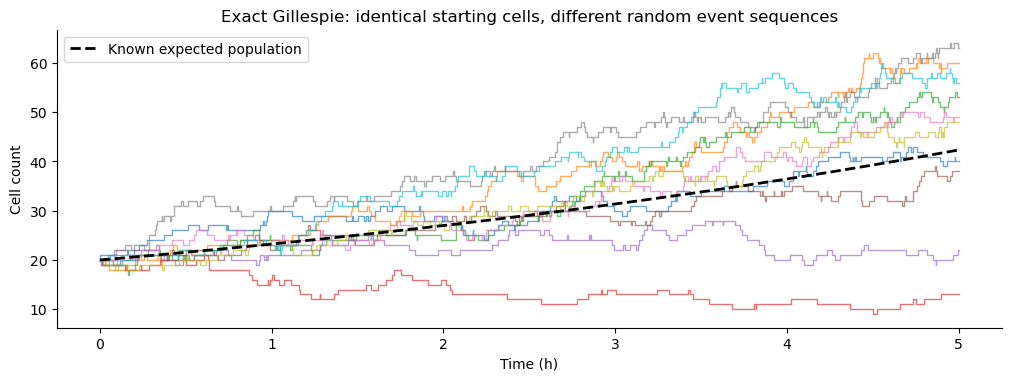

Exact SSA mean at 5 h: 43.55; theoretical mean: 42.34. Check passed.


In [3]:
def exact_birth_death(n0,birth_rate,death_rate,end,seed):
    rng=np.random.default_rng(seed);t=0.;n=int(n0);ts=[0.];ns=[n]
    while n>0:
        total=n*(birth_rate+death_rate)
        wait=rng.exponential(1/total)
        if t+wait>end:break
        t+=wait
        n+=1 if rng.random()<birth_rate/(birth_rate+death_rate) else -1
        ts.append(t);ns.append(n)
    ts.append(end);ns.append(n)
    return np.array(ts),np.array(ns)

small=[exact_birth_death(20,.55,.4,5,900+i) for i in range(400)]
final=np.array([n[-1] for t,n in small]);r=.55-.4
expected=20*np.exp(r*5)
variance=20*(.55+.4)/r*np.exp(r*5)*(np.exp(r*5)-1)
assert abs(final.mean()-expected)<5*np.sqrt(variance/len(final))
fig,ax=plt.subplots(figsize=(10,3.7),layout='constrained')
for t,n in small[:10]:ax.step(t,n,where='post',alpha=.65,lw=1)
grid=np.linspace(0,5,101);ax.plot(grid,20*np.exp(r*grid),'k--',lw=2,label='Known expected population')
ax.set(xlabel='Time (h)',ylabel='Cell count',title='Exact Gillespie: identical starting cells, different random event sequences')
ax.legend();plt.show();plt.close(fig)
print(f'Exact SSA mean at 5 h: {final.mean():.2f}; theoretical mean: {expected:.2f}. Check passed.')


## 3. The full stochastic community engine

This function applies the equations above. The random seed changes events, never intrinsic traits. Small steps are shortened further when mortality, drug clearance or expected nutrient depletion would change rates too much. Both pre-transfer and post-transfer states at 24 h are recorded, so the drop is not mistaken for killing.

In [4]:
ENGINE_VERSION='hybrid_bounded_leap_1'
from scipy.special import wrightomega

def remove_drug(a, B_R, duration, p):
    # Exact Michaelis–Menten integration while carrier biomass is held fixed.
    if a<=0 or B_R<=0 or duration<=0:return max(a,0.)
    z=np.log(a/p.km)+a/p.km-p.vmax*B_R*duration/p.km
    return float(p.km*wrightomega(z).real)

def simulate_events(p,mask,seed,dt_max=.05,save_dt=.25,random_events=True):
    rng=np.random.default_rng(seed)
    omega=float(p.cells_per_OD)
    # Integer allocation preserves the original total inoculum to the nearest cell.
    total0=int(round(p.initial_biomass*omega))
    n=np.full(57,total0//57,dtype=np.int64);n[:total0%57]+=1
    if not random_events:n=n.astype(float)
    food=int(round(p.food*omega));resource=food
    mu=INTRINSIC*(1-p.resistance_cost*mask)
    drug=0.;dead=0.;discarded=0.;capped=0;steps=0
    times=[];counts=[];foods=[];drugs=[];phases=[]
    def record(t,phase):
        times.append(float(t));counts.append(n.copy());foods.append(resource/omega)
        drugs.append(drug);phases.append(phase)
    record(0.,'pregrowth')
    stages=[(0.,p.pregrowth_h,'pregrowth'),
            (p.pregrowth_h,p.pregrowth_h+p.treatment_h,'treatment'),
            (p.pregrowth_h+p.treatment_h,p.pregrowth_h+p.treatment_h+p.recovery_h,'recovery')]
    for start,end,phase in stages:
        if phase=='treatment':drug=p.dose;record(start,phase)
        if phase=='recovery':
            pre=n.copy();discarded+=resource
            n=np.floor(n/p.dilution).astype(np.int64)
            if not random_events:n=n.astype(float)
            discarded+=float(np.sum(pre-n));post=n.copy()
            resource=food;drug=0.;record(start,phase)
        t=start
        for target in np.r_[np.arange(start+save_dt,end-1e-10,save_dt),end]:
            while t<target-1e-12:
                R=resource/omega
                g=mu*R/(p.half_saturation+R) if resource>0 else np.zeros(57)
                br=float(n[mask].sum()/omega)
                # Short steps limit changes in growth, death and the resource pool.
                h=min(dt_max,target-t,.03/max(float(mu.max()),1e-12))
                births_rate=float(np.sum(n*g))
                if resource>0 and births_rate>0:h=min(h,.1*resource/births_rate)
                if drug>.01*float(IC50.min()) and br>0:
                    h=min(h,.1*(p.km+drug)/(p.vmax*br))
                # Mortality bound uses the maximum possible antibiotic killing.
                h=min(h,.05/max(p.death_rate+p.gamma*float(g.max()),1e-12))
                ahalf=remove_drug(drug,br,h/2,p)
                q=(ahalf/IC50)**p.hill
                kill=np.where(mask,0.,p.gamma*q/(1+q)*g)
                hazard=p.death_rate+kill
                if random_events:
                    births=rng.poisson(n*g*h)
                    deaths=rng.binomial(n,-np.expm1(-hazard*h))
                    if births.sum()>resource:
                        # Accept uniformly from proposed birth events; no strain gets priority.
                        births=rng.multivariate_hypergeometric(births,int(resource))
                        capped+=1
                else:
                    births=n*g*h;deaths=n*(-np.expm1(-hazard*h))
                    if births.sum()>resource:
                        births*=resource/births.sum();capped+=1
                n=n+births-deaths
                resource-=births.sum();dead+=float(deaths.sum())
                if abs(resource)<1e-9:resource=0
                drug=remove_drug(ahalf,float(n[mask].sum()/omega),h/2,p)
                t+=h;steps+=1
            record(target,phase)
    counts=np.array(counts)
    error=(counts[-1].sum()+resource+dead+discarded-(total0+2*food))/omega
    return dict(t=np.array(times),N=counts/omega,cells=counts,R=np.array(foods),a=np.array(drugs),
                phase=np.array(phases),carrier=mask.copy(),pre_transfer=pre/omega,post_transfer=post/omega,
                budget_error=float(error),steps=np.array(steps),resource_caps=np.array(capped))

ENGINE_SHA256=hashlib.sha256("ENGINE_VERSION='hybrid_bounded_leap_1'\nfrom scipy.special import wrightomega\n\ndef remove_drug(a, B_R, duration, p):\n    # Exact Michaelis–Menten integration while carrier biomass is held fixed.\n    if a<=0 or B_R<=0 or duration<=0:return max(a,0.)\n    z=np.log(a/p.km)+a/p.km-p.vmax*B_R*duration/p.km\n    return float(p.km*wrightomega(z).real)\n\ndef simulate_events(p,mask,seed,dt_max=.05,save_dt=.25,random_events=True):\n    rng=np.random.default_rng(seed)\n    omega=float(p.cells_per_OD)\n    # Integer allocation preserves the original total inoculum to the nearest cell.\n    total0=int(round(p.initial_biomass*omega))\n    n=np.full(57,total0//57,dtype=np.int64);n[:total0%57]+=1\n    if not random_events:n=n.astype(float)\n    food=int(round(p.food*omega));resource=food\n    mu=INTRINSIC*(1-p.resistance_cost*mask)\n    drug=0.;dead=0.;discarded=0.;capped=0;steps=0\n    times=[];counts=[];foods=[];drugs=[];phases=[]\n    def record(t,phase):\n        times.append(float(t));counts.append(n.copy());foods.append(resource/omega)\n        drugs.append(drug);phases.append(phase)\n    record(0.,'pregrowth')\n    stages=[(0.,p.pregrowth_h,'pregrowth'),\n            (p.pregrowth_h,p.pregrowth_h+p.treatment_h,'treatment'),\n            (p.pregrowth_h+p.treatment_h,p.pregrowth_h+p.treatment_h+p.recovery_h,'recovery')]\n    for start,end,phase in stages:\n        if phase=='treatment':drug=p.dose;record(start,phase)\n        if phase=='recovery':\n            pre=n.copy();discarded+=resource\n            n=np.floor(n/p.dilution).astype(np.int64)\n            if not random_events:n=n.astype(float)\n            discarded+=float(np.sum(pre-n));post=n.copy()\n            resource=food;drug=0.;record(start,phase)\n        t=start\n        for target in np.r_[np.arange(start+save_dt,end-1e-10,save_dt),end]:\n            while t<target-1e-12:\n                R=resource/omega\n                g=mu*R/(p.half_saturation+R) if resource>0 else np.zeros(57)\n                br=float(n[mask].sum()/omega)\n                # Short steps limit changes in growth, death and the resource pool.\n                h=min(dt_max,target-t,.03/max(float(mu.max()),1e-12))\n                births_rate=float(np.sum(n*g))\n                if resource>0 and births_rate>0:h=min(h,.1*resource/births_rate)\n                if drug>.01*float(IC50.min()) and br>0:\n                    h=min(h,.1*(p.km+drug)/(p.vmax*br))\n                # Mortality bound uses the maximum possible antibiotic killing.\n                h=min(h,.05/max(p.death_rate+p.gamma*float(g.max()),1e-12))\n                ahalf=remove_drug(drug,br,h/2,p)\n                q=(ahalf/IC50)**p.hill\n                kill=np.where(mask,0.,p.gamma*q/(1+q)*g)\n                hazard=p.death_rate+kill\n                if random_events:\n                    births=rng.poisson(n*g*h)\n                    deaths=rng.binomial(n,-np.expm1(-hazard*h))\n                    if births.sum()>resource:\n                        # Accept uniformly from proposed birth events; no strain gets priority.\n                        births=rng.multivariate_hypergeometric(births,int(resource))\n                        capped+=1\n                else:\n                    births=n*g*h;deaths=n*(-np.expm1(-hazard*h))\n                    if births.sum()>resource:\n                        births*=resource/births.sum();capped+=1\n                n=n+births-deaths\n                resource-=births.sum();dead+=float(deaths.sum())\n                if abs(resource)<1e-9:resource=0\n                drug=remove_drug(ahalf,float(n[mask].sum()/omega),h/2,p)\n                t+=h;steps+=1\n            record(target,phase)\n    counts=np.array(counts)\n    error=(counts[-1].sum()+resource+dead+discarded-(total0+2*food))/omega\n    return dict(t=np.array(times),N=counts/omega,cells=counts,R=np.array(foods),a=np.array(drugs),\n                phase=np.array(phases),carrier=mask.copy(),pre_transfer=pre/omega,post_transfer=post/omega,\n                budget_error=float(error),steps=np.array(steps),resource_caps=np.array(capped))\n".encode()).hexdigest()

## 4. Check conservation and numerical step sensitivity first

Births move nutrient into living biomass; deaths move living biomass into a non-recycled death budget. Transfer discards cells and spent nutrient. Therefore **initial cells + supplied nutrient equivalents = live cells + remaining nutrient + dead + discarded**. This is checked for every run.

To separate time-step bias from stochastic spread, we also run a **mean-step numerical companion**: it uses expected births/deaths in the same stepper, without random draws. It is not the original ODE and is not treated as biological data. Smaller maximum steps should bring it closer to the original ODE away from cell-threshold differences. The table reports actual differences rather than promising exact agreement.

A finite step can introduce bias larger than the tiny stochastic spread at huge cell counts. The later comparison explicitly reports that possibility. If necessary, reduce `DT_MAX` and rerun; matching caches are distinguished by step size.

**Endpoint alignment:** the original code’s 0.1 h output grid can omit the exact 48 h endpoint (its final stored point can be 47.9 h). The ODE comparison here uses a 0.125 h output grid, which includes 4, 24 and 48 h exactly. This changes numerical output spacing only; the original equations, parameters governing biology, solver tolerances and treatment schedule are unchanged.

In [5]:
def at(sim,h):
    hit=np.flatnonzero(np.isclose(sim['t'],h,atol=1e-7))
    return sim['N'][hit[0] if len(hit) else np.argmin(np.abs(sim['t']-h))]

def metric_values(x,mask):
    b=float(x.sum())
    if b<=0:return dict(biomass=0.,shannon=np.nan,simpson=np.nan,inverse_simpson=np.nan,
                         resistant_share=np.nan,richness=0,extinct=True)
    p=x/b;positive=p>0;dominance=float(np.sum(p*p))
    return dict(biomass=b,shannon=float(-(p[positive]*np.log(p[positive])).sum()),
                simpson=1-dominance,inverse_simpson=1/dominance,
                resistant_share=float(x[mask].sum()/b),richness=int(((p>=BASE.detection_rel)&(x>0)).sum()),extinct=False)

def bray(x,y):
    return float(.5*np.abs(x/x.sum()-y/y.sum()).sum()) if x.sum()>0 and y.sum()>0 else np.nan

def safe_ratio(a,b):return float(a/b) if np.isfinite(a) and np.isfinite(b) and b>0 else np.nan

mask=np.zeros(57,bool);mask[29]=True
checks=model.check(verbose=False);display(checks)
assert checks.passed.all()
sensitivity=[]
for k in [0,1,20]:
    mask=np.zeros(57,bool);mask[np.random.default_rng(ASSIGNMENT_SEED).permutation(57)[:k]]=True
    ode=deterministic(mask,True)
    for step in [DT_MAX,DT_MAX/2,DT_MAX/4]:
        mean=simulate_events(BASE,mask,4,dt_max=step,random_events=False)
        a=metric_values(at(mean,48),mask);b=metric_values(at(ode,48),mask)
        sensitivity.append(dict(n_resistant=k,max_step_h=step,
            biomass_48h_mean_step=a['biomass'],biomass_48h_ODE=b['biomass'],
            absolute_biomass_error=abs(a['biomass']-b['biomass']),
            shannon_error=a['shannon']-b['shannon'],mass_error=mean['budget_error']))
        assert abs(mean['budget_error'])<1e-6
sensitivity=pd.DataFrame(sensitivity);display(sensitivity.round(7))
sensitivity.to_csv(OUT/'step_sensitivity_vs_original_ODE.csv',index=False)
assert bray(np.array([1.,0.]),np.array([0.,1.]))==1
assert bray(np.ones(57),np.ones(57))==0
assert np.isclose(metric_values(np.ones(57),np.zeros(57,bool))['shannon'],np.log(57))
assert np.isclose(metric_values(np.ones(57),np.zeros(57,bool))['simpson'],1-1/57)
assert np.isnan(metric_values(np.zeros(57),np.zeros(57,bool))['shannon'])
print('Metric definitions and conservation checks passed. Inspect the step errors before interpreting very small changes.')


,check,passed,detail
0,Mass balance closes: food supplied = biomass +...,True,max |error| = 4.2e-08
1,"No negative biomass, nutrient or drug",True,min = -1.0e-10
2,Dose 0 reproduces the untreated control exactly,True,max difference = 0.0e+00
3,A carrier that neither degrades nor pays a cos...,True,max difference across strains = 9.4e-01 (k30 i...
4,A drug added in stationary phase kills almost ...,True,treated/untreated biomass = 1.0000
5,The transfer is an exact 1:dilution split of t...,True,1:100; 0 strains fell below one cell and were ...
6,A strain removed at the one-cell floor never r...,True,0 strains reappeared
7,Resistant strains survive a dose that removes ...,True,"k30 biomass 0.945 OD, susceptible richness 0"
8,More resistant biomass leaves less drug behind,True,"drug at 24 h: 1 carrier 0, 8 carriers 0 ug/ml"
9,Degradation saturates above Km and is first-or...,True,doubling the drug multiplies the removal rate ...


,n_resistant,max_step_h,biomass_48h_mean_step,biomass_48h_ODE,absolute_biomass_error,shannon_error,mass_error
0,0,0.0500,0.000000,0.000000,0.000000,NaN,-0.0
1,0,0.0250,0.000000,0.000000,0.000000,NaN,0.0
2,0,0.0125,0.000000,0.000000,0.000000,NaN,-0.0
3,1,0.0500,0.941798,0.941501,0.000296,0.016306,-0.0
4,1,0.0250,0.941723,0.941501,0.000222,0.012425,-0.0
5,1,0.0125,0.941613,0.941501,0.000111,0.006315,0.0
6,20,0.0500,0.943750,0.943457,0.000293,0.002661,0.0
7,20,0.0250,0.943676,0.943457,0.000219,0.002047,-0.0
8,20,0.0125,0.943567,0.943457,0.000110,0.001086,-0.0


Metric definitions and conservation checks passed. Inspect the step errors before interpreting very small changes.


## 5. Design the two nested levels of repetition

Example: **5 carriers, assignment order 3, event repeat 7** has the same carrier identities as other event repeats in order 3, but different births/deaths. Another order may select different carriers. The original deterministic trajectory for that exact carrier set is saved separately.

Initial counts are fixed across all random-event repeats. We do not add random inoculum or transfer sampling. Carrier immunity, cost and per-OD drug degradation remain the original rules.

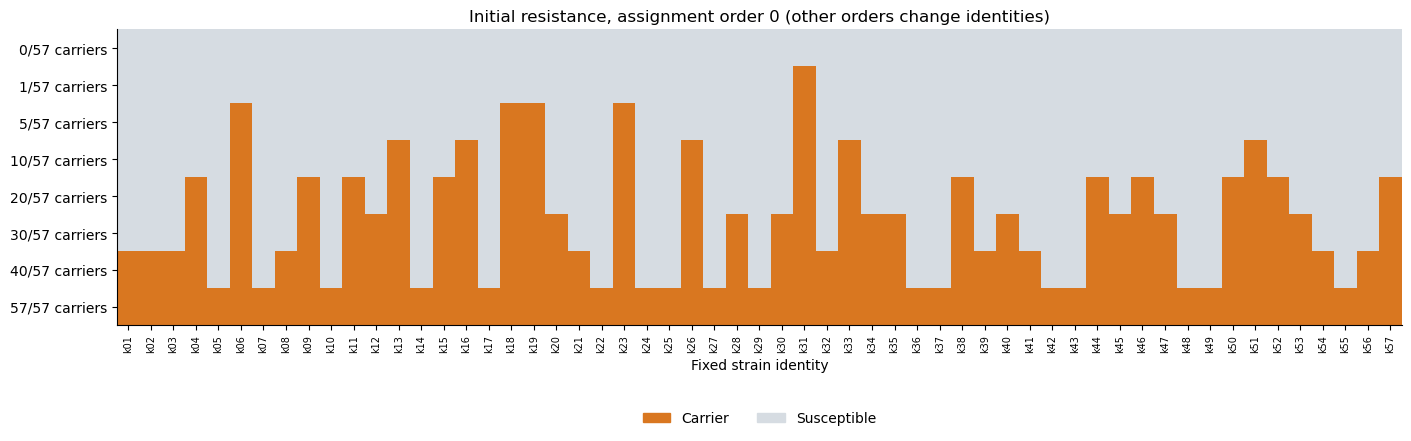

62 configurations; 1240 stochastic trajectories.


In [6]:
rng=np.random.default_rng(ASSIGNMENT_SEED);orders=[rng.permutation(57) for _ in range(N_ORDERS)]
MASKS={};rows=[]
for order_id,order in enumerate(orders):
    previous=np.zeros(57,bool)
    for k in sorted(k for k in COUNTS if 0<k<57):
        mask=np.zeros(57,bool);mask[order[:k]]=True
        assert np.all(~previous|mask);previous=mask.copy()
        name=f'order{order_id:02d}_k{k:02d}';MASKS[name]=mask
        rows.append(dict(scenario=name,order_id=order_id,n_resistant=k,reference=False))
for k in [0,57]:
    name=f'reference_k{k:02d}';MASKS[name]=np.full(57,k==57,dtype=bool)
    rows.append(dict(scenario=name,order_id=-1,n_resistant=k,reference=True))
design=pd.DataFrame(rows);design.to_csv(OUT/'design.csv',index=False)
assignments=pd.concat([pd.DataFrame(dict(scenario=d.scenario,strain=NAMES,carrier=MASKS[d.scenario]))
                       for d in design.itertuples()],ignore_index=True)
assignments.to_csv(OUT/'carrier_assignments.csv',index=False)
fig,ax=plt.subplots(figsize=(14,4.3),layout='constrained')
example=design[design.order_id.eq(0)|design.reference].sort_values('n_resistant')
ax.imshow(np.vstack([MASKS[s] for s in example.scenario]),aspect='auto',interpolation='nearest',
          cmap=ListedColormap(['#d6dce2','#d97720']),vmin=0,vmax=1)
ax.set_xticks(range(57),NAMES,rotation=90,fontsize=7)
ax.set_yticks(range(len(example)),[f'{k}/57 carriers' for k in example.n_resistant])
ax.set(title='Initial resistance, assignment order 0 (other orders change identities)',xlabel='Fixed strain identity')
ax.legend(handles=[Patch(color='#d97720',label='Carrier'),Patch(color='#d6dce2',label='Susceptible')],
          loc='upper center',bbox_to_anchor=(.5,-.25),ncol=2,frameon=False)
fig.savefig(FIGURES/'01_initial_resistance.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
print(len(design),'configurations;',len(design)*N_REPEATS*2,'stochastic trajectories.')


## 6. Run and save every stochastic repeat

Every cache includes full saved trajectories (`N` in OD, time, nutrient, drug, phase, carrier mask, transfer states and mass-balance diagnostics). Cache identity includes source hashes, parameters, event seed, step size and carrier mask. Changing a setting cannot silently load a run from a different setting.

The event seed is reproducible from the assignment, carrier count, repeat and treatment arm. The two biological noise levels are retained as separate columns. Identical event seeds replay identical trajectories; deterministic reruns always agree.

In [7]:
STOCH={};ODE={};MEAN={};audit=[]
SAVE_KEYS=['t','N','R','a','phase','carrier','pre_transfer','post_transfer','budget_error','steps','resource_caps']
def cached_stochastic(d,rep,treated):
    seed=int(np.random.SeedSequence([EVENT_SEED,d.order_id+1,d.n_resistant,rep,int(treated)]).generate_state(1)[0])
    mask=MASKS[d.scenario];p=replace(BASE,n_resistant=d.n_resistant,dose=DOSE if treated else 0.)
    payload=dict(model=MODEL_SHA256,engine=ENGINE_SHA256,seed=seed,mask=mask.tolist(),
                 parameters=vars(p),dt_max=DT_MAX,save_dt=SAVE_DT)
    key=hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest();path=CACHE/(key+'.npz')
    if path.exists() and not RECOMPUTE:
        with np.load(path,allow_pickle=False) as data:s={k:data[k].copy() for k in SAVE_KEYS}
    else:
        s=simulate_events(p,mask,seed,dt_max=DT_MAX,save_dt=SAVE_DT)
        tmp=path.with_suffix('.tmp')
        with tmp.open('wb') as f:np.savez_compressed(f,**{k:s[k] for k in SAVE_KEYS})
        tmp.replace(path)
        s={k:s[k] for k in SAVE_KEYS}
    assert np.isfinite(s['N']).all() and s['N'].min()>=0
    np.testing.assert_allclose(s['N']*p.cells_per_OD,np.rint(s['N']*p.cells_per_OD),atol=1e-5,rtol=0)
    assert abs(float(s['budget_error']))<1e-6
    np.testing.assert_array_equal(s['carrier'],mask)
    expected=np.floor(np.rint(s['pre_transfer']*p.cells_per_OD)/p.dilution)/p.cells_per_OD
    np.testing.assert_allclose(s['post_transfer'],expected,atol=1e-15)
    assert (s['R']>=0).all() and (s['a']>=0).all()
    zero=s['N']==0
    assert not np.any((np.cumsum(zero,axis=0)>0)&(s['N']>0))
    return s,seed,path.name
for d in design.itertuples():
    for treated in [False,True]:
        ODE[(d.scenario,treated)]=deterministic(MASKS[d.scenario],treated)
        if d.order_id in [0,-1]:
            p=replace(BASE,n_resistant=d.n_resistant,dose=DOSE if treated else 0.)
            MEAN[(d.scenario,treated)]=simulate_events(p,MASKS[d.scenario],0,dt_max=DT_MAX,save_dt=SAVE_DT,random_events=False)
        for rep in range(N_REPEATS):
            s,seed,filename=cached_stochastic(d,rep,treated);STOCH[(d.scenario,rep,treated)]=s
            audit.append(dict(scenario=d.scenario,order_id=d.order_id,n_resistant=d.n_resistant,repeat=rep,
                treated=treated,event_seed=seed,cache_file=filename,mass_error=float(s['budget_error']),
                resource_caps=int(s['resource_caps']),internal_steps=int(s['steps'])))
    print(d.scenario,': original ODE +',2*N_REPEATS,'event trajectories saved',flush=True)
audit=pd.DataFrame(audit);audit.to_csv(OUT/'simulation_audit.csv',index=False)
print('All simulations complete; no negative populations, nutrient or drug; transfer and mass balance verified.')


order00_k01 : original ODE + 20 event trajectories saved
order00_k05 : original ODE + 20 event trajectories saved
order00_k10 : original ODE + 20 event trajectories saved
order00_k20 : original ODE + 20 event trajectories saved
order00_k30 : original ODE + 20 event trajectories saved
order00_k40 : original ODE + 20 event trajectories saved
order01_k01 : original ODE + 20 event trajectories saved
order01_k05 : original ODE + 20 event trajectories saved
order01_k10 : original ODE + 20 event trajectories saved
order01_k20 : original ODE + 20 event trajectories saved
order01_k30 : original ODE + 20 event trajectories saved
order01_k40 : original ODE + 20 event trajectories saved
order02_k01 : original ODE + 20 event trajectories saved
order02_k05 : original ODE + 20 event trajectories saved
order02_k10 : original ODE + 20 event trajectories saved
order02_k20 : original ODE + 20 event trajectories saved
order02_k30 : original ODE + 20 event trajectories saved
order02_k40 : original ODE + 20

## 7. Calculate metrics on each individual trajectory

- **Shannon:** H = −Σ p ln p. Initial value is near ln(57) ≈ 4.04. Higher means more diversity/evenness.
- **Gini–Simpson:** 1 − Σp². Higher means more diversity; this is the Simpson convention plotted here. Inverse Simpson (1/Σp²) is also exported as an effective number of strains.
- **Bray–Curtis to pretreatment baseline:** ½Σ|pᵢ(t)−pᵢ(4 h)|. Lower means less composition change; it is not a species-level similarity score.
- **Shannon retention:** H(t)/H(4 h). Higher is usually closer to retained diversity, but values above 1 are possible. It does not capture biomass loss.
- **Extinction:** total biomass = 0. Diversity and composition are undefined, not zero, for an empty community. Richness refers to the model’s relative detection threshold, not proof of extinction.

Baseline is each repeat’s own community at 4 h. At 24 h use the pre-dilution state. Metrics are evaluated before aggregation, so averages do not invent a community that never existed. The stored timecourse includes duplicate phase-boundary times; phase labels distinguish before and after transfer.

In [8]:
records=[];sample_records=[];contributions=[]
for d in design.itertuples():
    mask=MASKS[d.scenario]
    for treated in [False,True]:
        for rep in range(N_REPEATS):
            sim=STOCH[(d.scenario,rep,treated)];baseline=at(sim,4.)
            h0=metric_values(baseline,mask)['shannon'];b0=baseline.sum()
            for j,(time,x) in enumerate(zip(sim['t'],sim['N'])):
                m=metric_values(x,mask)
                records.append(dict(scenario=d.scenario,order_id=d.order_id,n_resistant=d.n_resistant,
                    reference=d.reference,repeat=rep,treated=treated,record_index=j,hour=float(time),phase=sim['phase'][j],
                    **m,shannon_retention=safe_ratio(m['shannon'],h0),bray_curtis=bray(x,baseline),
                    baseline_carrier_OD=float(baseline[mask].sum())))
            for hour in [0.,4.,6.,24.,48.]:
                x=at(sim,hour);m=metric_values(x,mask)
                sample_records.append(dict(scenario=d.scenario,order_id=d.order_id,n_resistant=d.n_resistant,
                    reference=d.reference,repeat=rep,treated=treated,hour=hour,**m,
                    shannon_retention=safe_ratio(m['shannon'],h0),bray_curtis=bray(x,baseline),
                    baseline_carrier_OD=float(baseline[mask].sum())))
            if treated:
                end=at(sim,48.)
                delta=end/end.sum()-baseline/baseline.sum() if end.sum()>0 and baseline.sum()>0 else np.full(57,np.nan)
                for i,name in enumerate(NAMES):
                    contributions.append(dict(scenario=d.scenario,order_id=d.order_id,n_resistant=d.n_resistant,
                        repeat=rep,strain=name,carrier=bool(mask[i]),signed_relative_shift=delta[i],
                        BC_contribution=.5*abs(delta[i])))
curves=pd.DataFrame(records);samples=pd.DataFrame(sample_records);species=pd.DataFrame(contributions)
curves.to_csv(OUT/'individual_community_timecourses.csv.gz',index=False,compression='gzip')
samples.to_csv(OUT/'individual_sampling_metrics.csv',index=False)
species.to_csv(OUT/'strain_restructuring_48h.csv.gz',index=False,compression='gzip')
# Assignments and random repeats are distinct identifiers throughout.
assert not samples.duplicated(['scenario','repeat','treated','hour']).any()
display(samples[samples.hour.eq(48)].head(12).round(5))


,scenario,order_id,n_resistant,reference,repeat,treated,hour,biomass,shannon,simpson,inverse_simpson,resistant_share,richness,extinct,shannon_retention,bray_curtis,baseline_carrier_OD
4,order00_k01,0,1,False,0,False,48.0,0.94335,3.90035,0.97716,43.77674,0.05032,57,False,0.96636,0.17134,0.00089
9,order00_k01,0,1,False,1,False,48.0,0.94336,3.90078,0.97719,43.83144,0.04984,57,False,0.96647,0.17154,0.00088
14,order00_k01,0,1,False,2,False,48.0,0.94336,3.90054,0.97717,43.80776,0.05014,57,False,0.96643,0.17116,0.00089
19,order00_k01,0,1,False,3,False,48.0,0.94336,3.90090,0.97719,43.83766,0.05012,57,False,0.96651,0.17106,0.00089
24,order00_k01,0,1,False,4,False,48.0,0.94334,3.90054,0.97718,43.81218,0.05004,57,False,0.96642,0.17144,0.00089
29,order00_k01,0,1,False,5,False,48.0,0.94336,3.90062,0.97717,43.79664,0.05051,57,False,0.96643,0.17116,0.00089
34,order00_k01,0,1,False,6,False,48.0,0.94335,3.90054,0.97717,43.80280,0.05019,57,False,0.96643,0.17118,0.00089
39,order00_k01,0,1,False,7,False,48.0,0.94337,3.90015,0.97715,43.76746,0.05024,57,False,0.96633,0.17147,0.00089
44,order00_k01,0,1,False,8,False,48.0,0.94335,3.90060,0.97717,43.80295,0.05011,57,False,0.96643,0.17133,0.00089
49,order00_k01,0,1,False,9,False,48.0,0.94336,3.90045,0.97717,43.79829,0.05020,57,False,0.96640,0.17121,0.00089


## 8. Absolute biomass with continuous strain bands

These are **event repeat 0, assignment order 0**, plus the shared reference assignments. This is one actual simulated trajectory per panel, not the composition of an averaged population. Each of the 57 bands has a fixed identity color. Total height is biomass in OD; band thickness divided by total height is relative abundance at that time. All panels share the same scale.

Left = untreated; right = treated. The 24 h drop is dilution. An extinct community may be hard to distinguish from very low biomass on this common scale; the extinction analysis below makes that explicit.

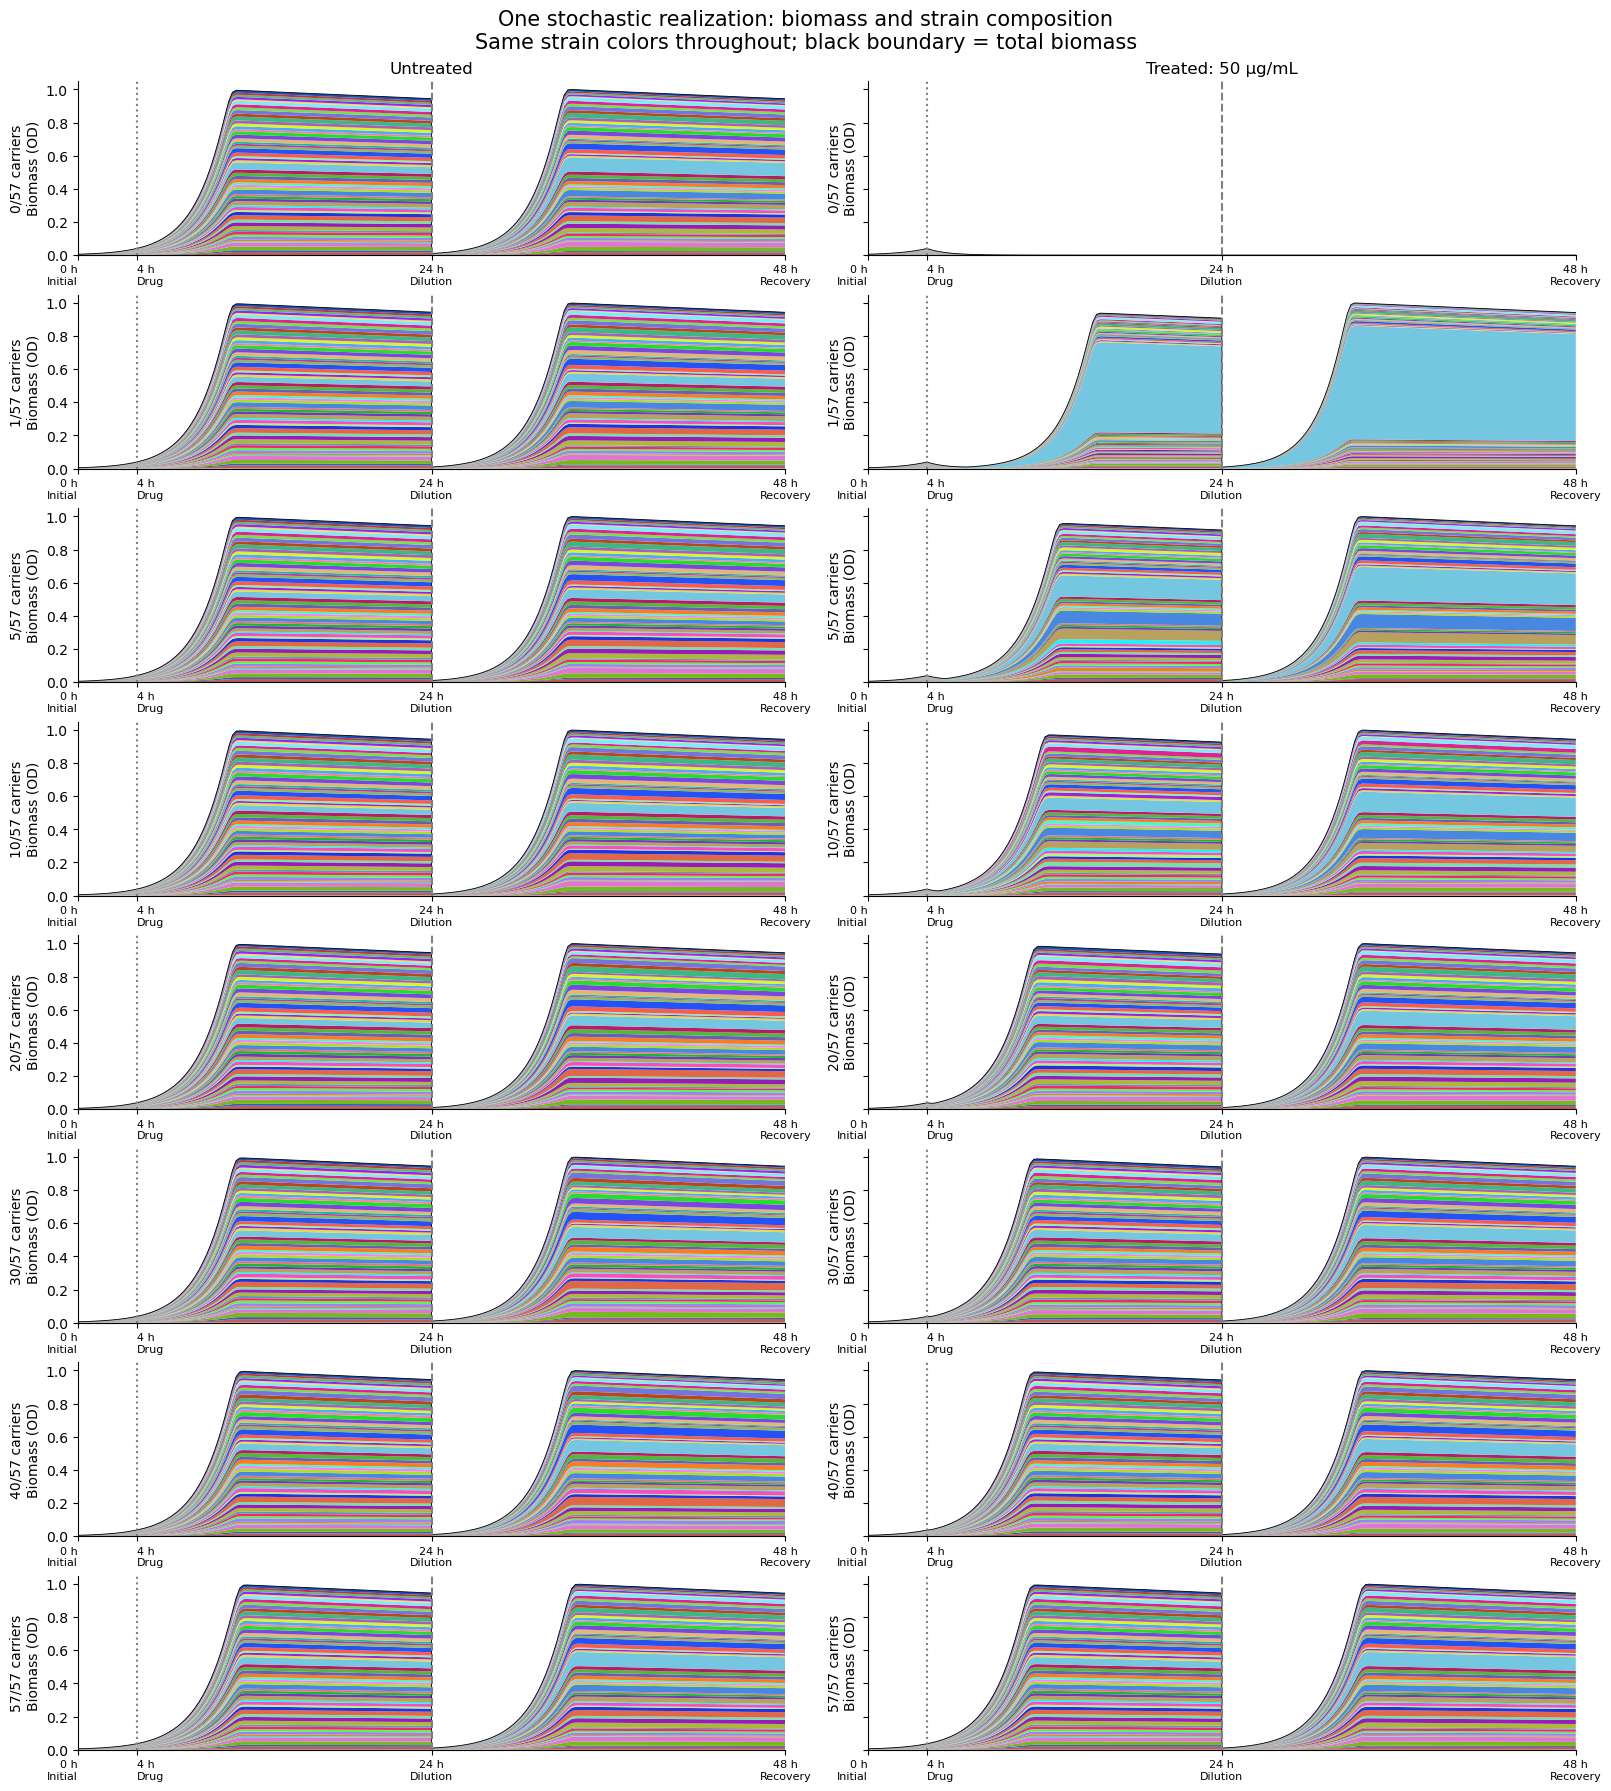

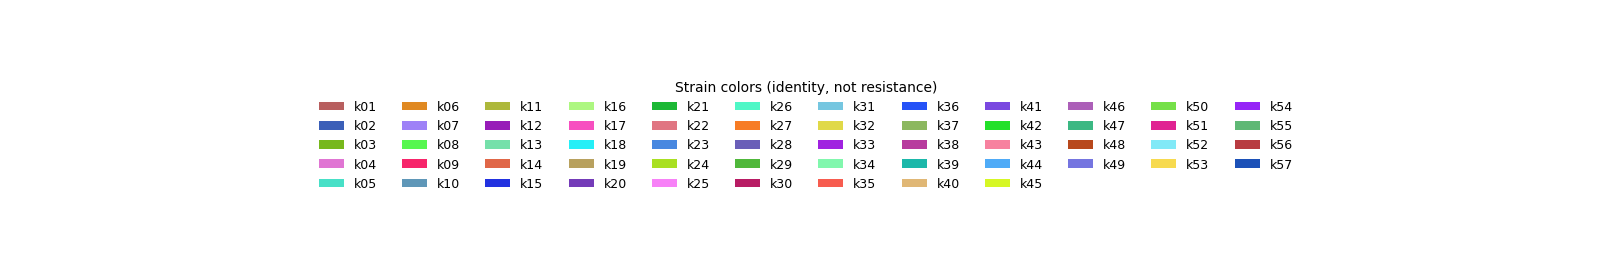

In [9]:
SC=[colorsys.hsv_to_rgb((i*.61803398875)%1,[.48,.68,.85][i%3],[.72,.88,.97][(i//3)%3]) for i in range(57)]
representative=design[design.order_id.eq(0)|design.reference].sort_values('n_resistant')
fig,axes=plt.subplots(len(representative),2,figsize=(16,2.1*len(representative)+1),sharex=True,sharey=True,
                       squeeze=False,layout='constrained')
max_b=max(STOCH[(s,0,t)]['N'].sum(axis=1).max() for s in representative.scenario for t in [False,True])
for row,d in enumerate(representative.itertuples()):
    for col,treated in enumerate([False,True]):
        sim=STOCH[(d.scenario,0,treated)];ax=axes[row,col]
        ax.stackplot(sim['t'],sim['N'].T,colors=SC,linewidth=0)
        ax.plot(sim['t'],sim['N'].sum(axis=1),color='black',lw=.6)
        ax.axvline(4,color='gray',ls=':');ax.axvline(24,color='gray',ls='--')
        ax.set_xticks([0,4,24,48],['0 h\nInitial','4 h\nDrug','24 h\nDilution','48 h\nRecovery'],fontsize=8)
        ax.tick_params(labelbottom=True);ax.get_xticklabels()[0].set_ha('right');ax.get_xticklabels()[1].set_ha('left')
        ax.set(xlim=(0,48),ylim=(0,max_b*1.05),ylabel=f'{d.n_resistant}/57 carriers\nBiomass (OD)')
        if row==0:ax.set_title('Untreated' if not treated else f'Treated: {DOSE:g} µg/mL')
fig.suptitle('One stochastic realization: biomass and strain composition\nSame strain colors throughout; black boundary = total biomass',fontsize=15)
fig.savefig(FIGURES/'02_absolute_strain_trajectories.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(16,2.6),layout='constrained');ax.axis('off')
ax.legend(handles=[Patch(facecolor=c,label=n) for c,n in zip(SC,NAMES)],loc='center',ncol=12,frameon=False,fontsize=9,title='Strain colors (identity, not resistance)')
fig.savefig(FIGURES/'strain_color_key.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)


## 9. Shannon and Simpson diversity over time

To isolate random-event variation, this figure uses **assignment order 0** (and the two reference assignments). Each carrier count has a distinct color. Lines are means of per-run metrics; shading is ±1 standard deviation over the 10 event repeats of that exact assignment. Undefined diversity after extinction is not averaged as zero; sample availability is exported.

At the original large cell counts, shading can be very narrow. That is a result, not a plotting error. We do not change the population scale to manufacture visible stochasticity.

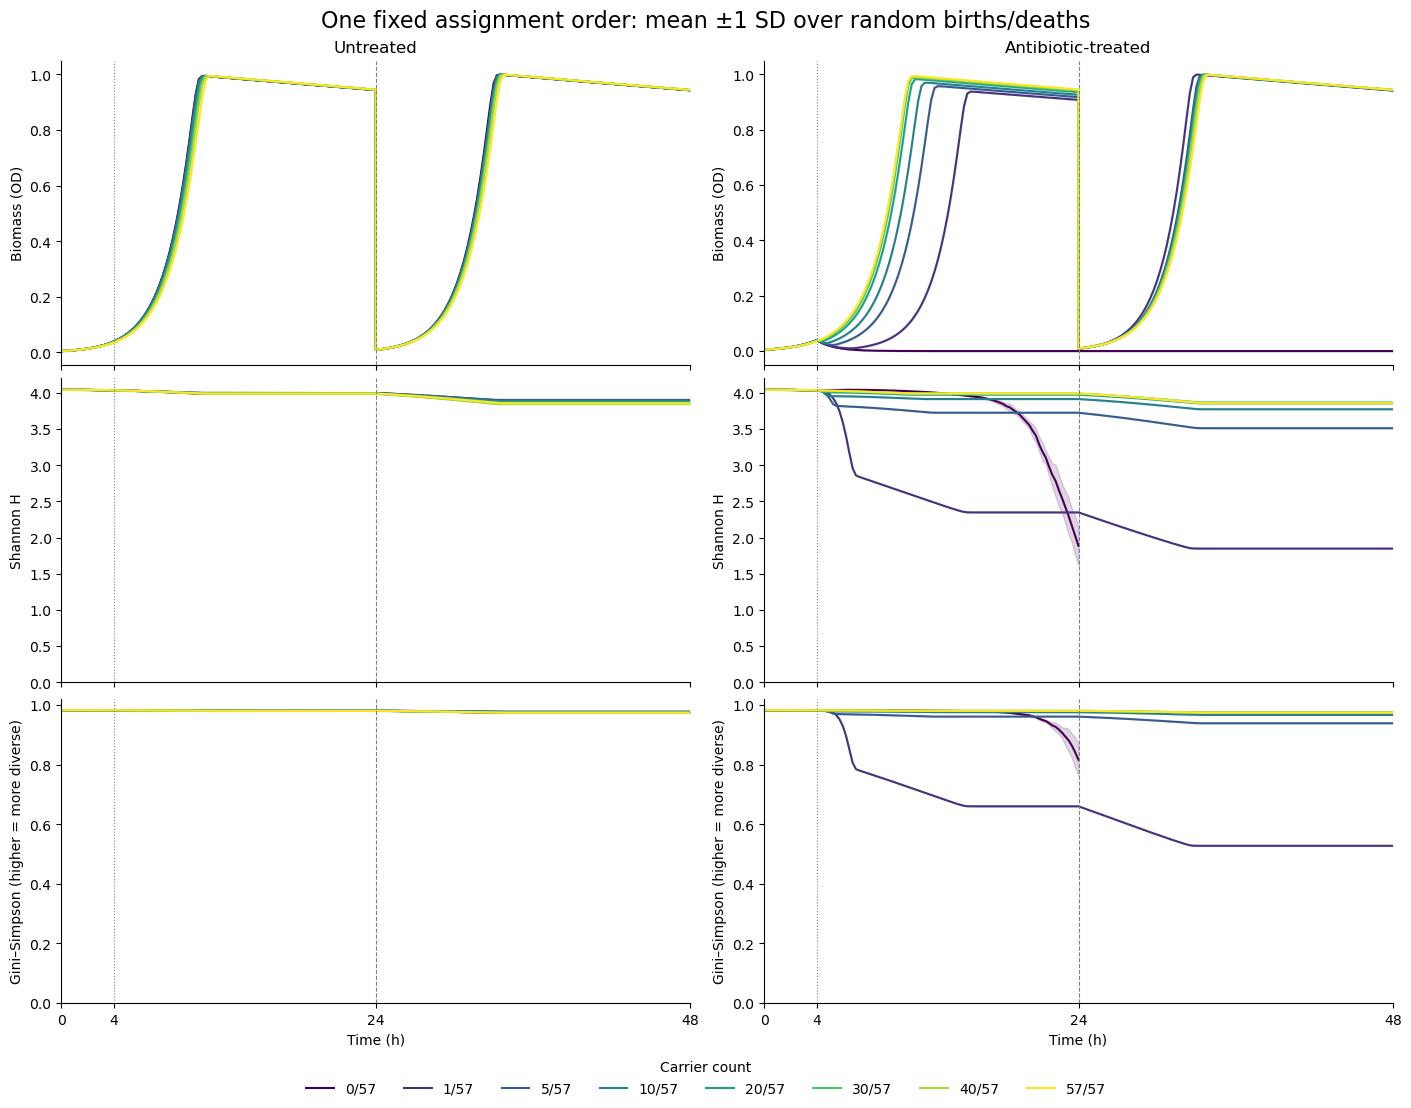

In [10]:
COUNT_POS={k:i for i,k in enumerate(COUNTS)}
CC={k:plt.get_cmap('viridis')(i/max(len(COUNTS)-1,1)) for i,k in enumerate(sorted(COUNTS))}
fig,axes=plt.subplots(3,2,figsize=(14,11),sharex=True,layout='constrained')
for col,treated in enumerate([False,True]):
    for d in representative.itertuples():
        z=curves[curves.scenario.eq(d.scenario)&curves.treated.eq(treated)]
        # Record index preserves both sides of the transfer; same output schedule in all repeats.
        for row,(metric,label) in enumerate([('biomass','Biomass (OD)'),('shannon','Shannon H'),('simpson','Gini–Simpson (higher = more diverse)')]):
            stats=z.groupby('record_index').agg(hour=('hour','first'),mean=(metric,'mean'),sd=(metric,'std'))
            ax=axes[row,col];ax.plot(stats.hour,stats['mean'],color=CC[d.n_resistant],label=f'{d.n_resistant}/57')
            ax.fill_between(stats.hour,stats['mean']-stats.sd,stats['mean']+stats.sd,color=CC[d.n_resistant],alpha=.16)
            ax.set_ylabel(label)
for ax in axes.flat:
    ax.axvline(4,color='gray',ls=':',lw=.8);ax.axvline(24,color='gray',ls='--',lw=.8);ax.set_xticks([0,4,24,48]);ax.set_xlim(0,48)
axes[0,0].set_title('Untreated');axes[0,1].set_title('Antibiotic-treated')
axes[2,0].set_xlabel('Time (h)');axes[2,1].set_xlabel('Time (h)')
for ax in axes[1]:ax.set_ylim(0,np.log(57)*1.04)
for ax in axes[2]:ax.set_ylim(0,1.02)
handles,labels=axes[0,0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=8,frameon=False,title='Carrier count')
fig.suptitle('One fixed assignment order: mean ±1 SD over random births/deaths',fontsize=16)
fig.savefig(FIGURES/'03_diversity_and_biomass_over_time.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)


## 10. Diversity versus number of resistant strains, colored by assignment trial

Each point summarizes 10 event repeats of **one assignment**. Color identifies assignment order 0–9. Error bars show **±1 SD within that assignment**. Differences between colored points show carrier-identity effects; error-bar size shows random-event variation. Gray squares represent shared endpoint assignments. Horizontal offsets separate overlapping trials without changing the true carrier counts.

Columns are 6 h (early exposure), 24 h (pre-transfer) and 48 h (post-regrowth). Calculate diversity separately in each repeat, then summarize. The table records how many repeats have defined diversity, so extinction is not silently hidden.

Carrier counts are displayed as equally spaced categories so 0 and 1 are easy to distinguish; their numeric labels give the true counts.

A “No survivors” label means all event repeats of that assignment are extinct, so diversity is undefined. It is not plotted as zero diversity. Error bars smaller than their markers indicate little random-event variability.

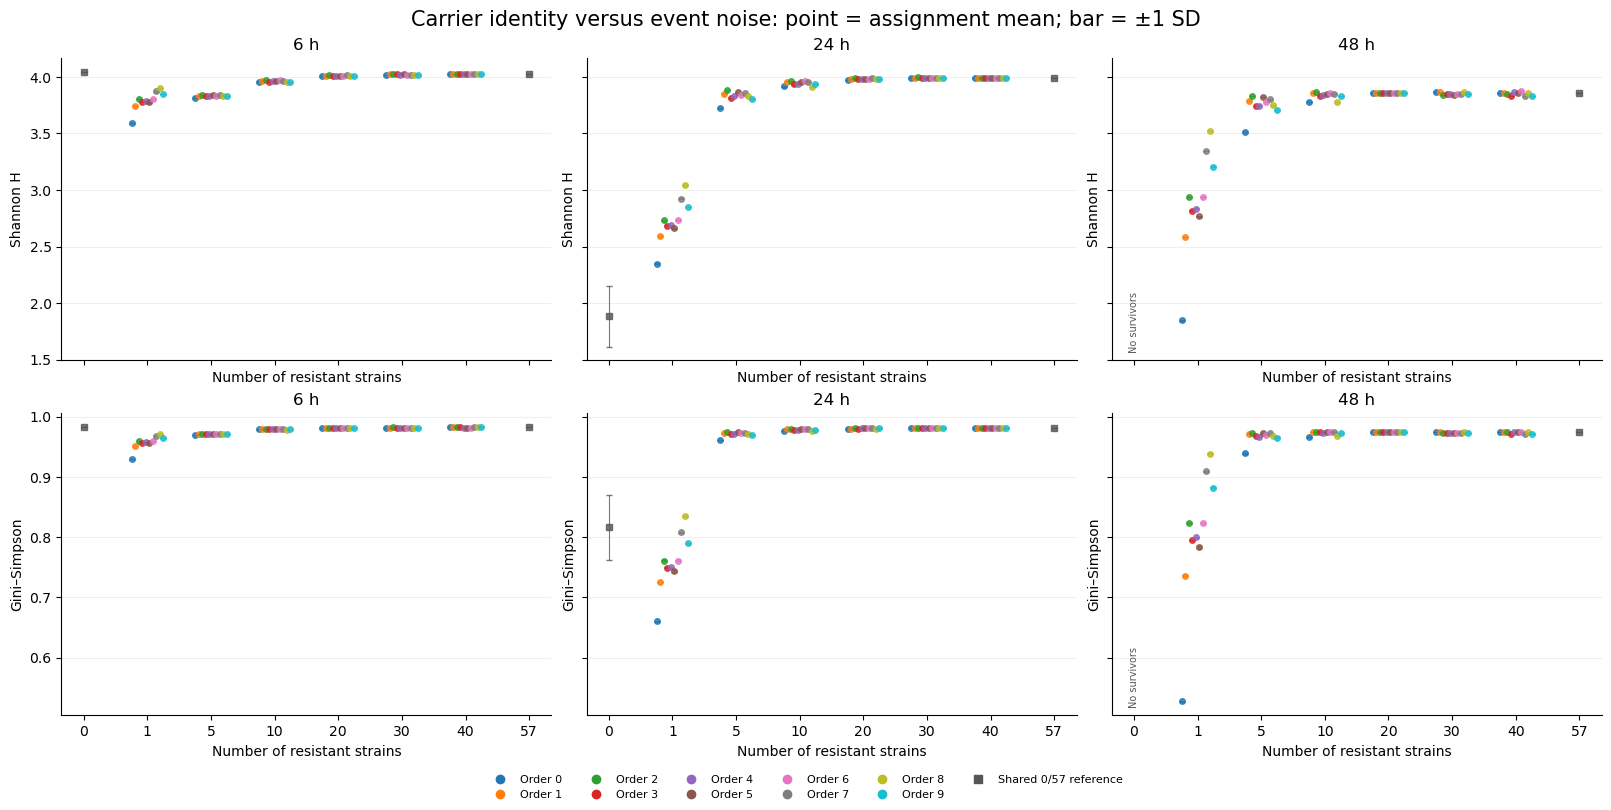

In [11]:
treated_samples=samples[samples.treated]
assignment_stats=treated_samples.groupby(['scenario','order_id','n_resistant','reference','hour']).agg(
    shannon_mean=('shannon','mean'),shannon_sd=('shannon','std'),shannon_n=('shannon','count'),
    simpson_mean=('simpson','mean'),simpson_sd=('simpson','std'),
    bc_mean=('bray_curtis','mean'),bc_sd=('bray_curtis','std'),
    retention_mean=('shannon_retention','mean'),retention_sd=('shannon_retention','std'),
    carrier_baseline_mean=('baseline_carrier_OD','mean'),extinction_probability=('extinct','mean')).reset_index()
assignment_stats.to_csv(OUT/'assignment_means_and_within_assignment_SD.csv',index=False)
ORDER_COLORS={i:plt.get_cmap('tab10')(i%10) for i in range(N_ORDERS)}
fig,axes=plt.subplots(2,3,figsize=(16,8),sharex=True,sharey='row',layout='constrained')
for col,hour in enumerate([6.,24.,48.]):
    g=assignment_stats[assignment_stats.hour.eq(hour)]
    for row,(mean,sd,title) in enumerate([('shannon_mean','shannon_sd','Shannon H'),('simpson_mean','simpson_sd','Gini–Simpson')]):
        ax=axes[row,col]
        for d in g.itertuples():
            offset=0 if d.reference else (d.order_id-(N_ORDERS-1)/2)*.055
            ax.errorbar(COUNT_POS[d.n_resistant]+offset,getattr(d,mean),yerr=getattr(d,sd),fmt='s' if d.reference else 'o',
                        color='#555555' if d.reference else ORDER_COLORS[d.order_id],ms=4,capsize=2,alpha=.8,lw=.8)
            if d.shannon_n==0:
                ax.text(COUNT_POS[d.n_resistant]+offset,.025,'No survivors',transform=ax.get_xaxis_transform(),
                        ha='center',va='bottom',rotation=90,fontsize=7,color='#555555')
        ax.set(title=f'{hour:g} h',ylabel=title,xticks=range(len(COUNTS)),xticklabels=COUNTS,xlabel='Number of resistant strains')
        ax.grid(axis='y',alpha=.2)
fig.legend(handles=[plt.Line2D([0],[0],ls='',marker='o',color=ORDER_COLORS[i],label=f'Order {i}') for i in range(N_ORDERS)]
    +[plt.Line2D([0],[0],ls='',marker='s',color='#555555',label='Shared 0/57 reference')],loc='outside lower center',ncol=6,frameon=False,fontsize=8)
fig.suptitle('Carrier identity versus event noise: point = assignment mean; bar = ±1 SD',fontsize=15)
fig.savefig(FIGURES/'04_diversity_vs_resistant_count.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)


## 11. Do identical communities follow different stochastic trajectories?

We preselect **1 carrier, assignment order 0**; we do not choose whichever example has the biggest spread. All lines below have identical traits, carrier identity, inoculum, dose and protocol. Only the event seed changes.

The first panel overlays stochastic biomass with the original ODE and the finite-step mean companion. The other panels zoom into deviations from the stochastic ensemble mean, so small differences remain visible. These deviations do not change the biological population scale. Separation from the ODE can include numerical approximation and extinction/rounding differences; it is not automatically an effect of randomness.

The pairwise Bray–Curtis panel compares repeats of the same configuration. This measures stochastic divergence, distinct from change relative to each repeat's pretreatment baseline.

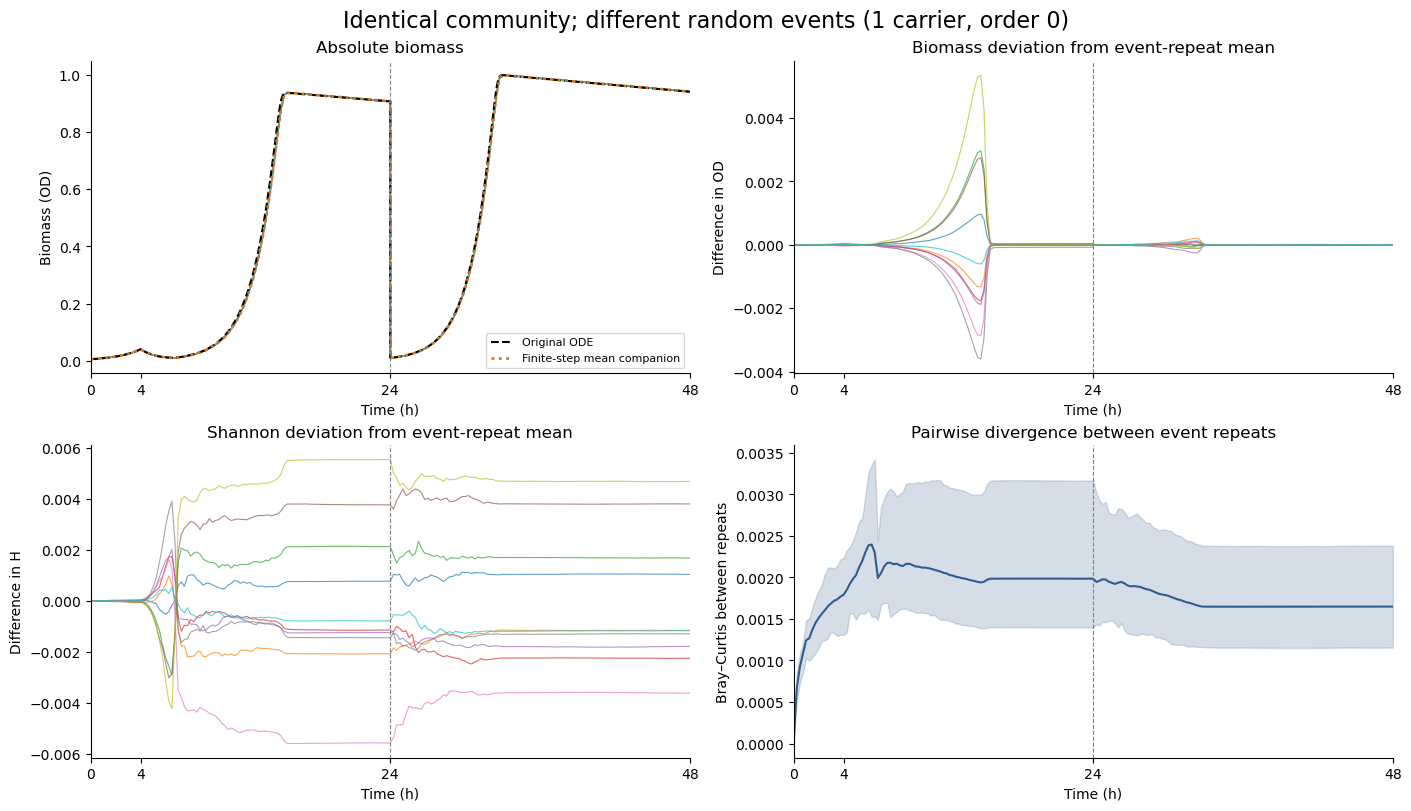

,scenario,metric,ODE,mean_step,stochastic_mean,stochastic_SD,mean_step_minus_ODE
0,reference_k00,biomass,0.000000,0.000000,0.000000,0.000000,0.000000
1,reference_k00,shannon,NaN,NaN,NaN,NaN,NaN
2,order00_k01,biomass,0.941501,0.941798,0.941795,0.000008,0.000296
3,order00_k01,shannon,1.831320,1.847627,1.847455,0.002707,0.016306
4,order00_k05,biomass,0.942838,0.943132,0.943136,0.000003,0.000294
5,order00_k05,shannon,3.505944,3.511790,3.511824,0.001365,0.005846
6,order00_k10,biomass,0.943175,0.943469,0.943465,0.000008,0.000293
7,order00_k10,shannon,3.770229,3.773615,3.773901,0.000487,0.003387
8,order00_k20,biomass,0.943457,0.943750,0.943751,0.000005,0.000293
9,order00_k20,shannon,3.853245,3.855907,3.855827,0.000343,0.002661


Some finite-step offsets exceed the event SD. Do not interpret an ODE–stochastic gap as pure randomness; inspect the step-sensitivity table and reduce DT_MAX for precise comparisons.


In [12]:
example_name=design[(design.order_id==0)&(design.n_resistant==1)].scenario.iloc[0]
example_runs=[STOCH[(example_name,r,True)] for r in range(N_REPEATS)]
time=example_runs[0]['t'];matB=np.array([s['N'].sum(axis=1) for s in example_runs])
matH=np.array([[metric_values(x,s['carrier'])['shannon'] for x in s['N']] for s in example_runs])
fig,axes=plt.subplots(2,2,figsize=(14,8),layout='constrained')
for rep in range(N_REPEATS):
    color=plt.get_cmap('tab10')(rep%10)
    axes[0,0].plot(time,matB[rep],color=color,alpha=.6,lw=1)
    axes[0,1].plot(time,matB[rep]-matB.mean(axis=0),color=color,alpha=.7,lw=.8)
    axes[1,0].plot(time,matH[rep]-np.nanmean(matH,axis=0),color=color,alpha=.7,lw=.8)
ode=ODE[(example_name,True)];mean=MEAN[(example_name,True)]
axes[0,0].plot(ode['t'],ode['N'].sum(axis=1),'k--',label='Original ODE')
axes[0,0].plot(mean['t'],mean['N'].sum(axis=1),color='#d97720',ls=':',lw=2,label='Finite-step mean companion')
axes[0,0].legend(fontsize=8)
pairs=[]
for i in range(N_REPEATS):
    for j in range(i+1,N_REPEATS):pairs.append([bray(x,y) for x,y in zip(example_runs[i]['N'],example_runs[j]['N'])])
pairs=np.array(pairs)
axes[1,1].plot(time,np.nanmean(pairs,axis=0),color='#315c8b')
axes[1,1].fill_between(time,np.nanmin(pairs,axis=0),np.nanmax(pairs,axis=0),alpha=.2,color='#315c8b')
for ax,title,y in zip(axes.flat,['Absolute biomass','Biomass deviation from event-repeat mean','Shannon deviation from event-repeat mean','Pairwise divergence between event repeats'],
 ['Biomass (OD)','Difference in OD','Difference in H','Bray–Curtis between repeats']):
    ax.set(title=title,ylabel=y,xlabel='Time (h)',xlim=(0,48),xticks=[0,4,24,48]);ax.axvline(24,color='gray',ls='--',lw=.8)
fig.suptitle('Identical community; different random events (1 carrier, order 0)',fontsize=16)
fig.savefig(FIGURES/'05_stochastic_trajectory_divergence.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
# Explicitly compare approximation bias with demographic spread at the endpoint.
bias=[]
for d in representative.itertuples():
    for metric in ['biomass','shannon']:
        v=samples[(samples.scenario==d.scenario)&samples.treated&samples.hour.eq(48)][metric]
        orig=metric_values(at(ODE[(d.scenario,True)],48),MASKS[d.scenario])[metric]
        numerical=metric_values(at(MEAN[(d.scenario,True)],48),MASKS[d.scenario])[metric]
        bias.append(dict(scenario=d.scenario,metric=metric,ODE=orig,mean_step=numerical,
                         stochastic_mean=v.mean(),stochastic_SD=v.std(),mean_step_minus_ODE=numerical-orig))
bias=pd.DataFrame(bias);display(bias.round(7));bias.to_csv(OUT/'numerical_bias_vs_stochastic_spread.csv',index=False)

finite_bias=bias.dropna()
if (finite_bias.mean_step_minus_ODE.abs()>finite_bias.stochastic_SD).any():
    print("Some finite-step offsets exceed the event SD. Do not interpret an ODE–stochastic gap as pure randomness; inspect the step-sensitivity table and reduce DT_MAX for precise comparisons.")


## 12. Bray–Curtis restructuring and the strains responsible

Bray–Curtis is a **whole-community** distance. To identify which strains drive it, use each strain's contribution **½|pᵢ(48) − pᵢ(4)|**. Contributions sum exactly to the community’s Bray–Curtis distance for each nonempty run. A separate signed shift tells whether the strain gained or lost relative abundance. A strain's relative gain does not necessarily mean its absolute biomass increased.

The first plot compares assignment means (bars = within-assignment event SD). The heatmaps show the 12 strains with the largest mean contribution across nonempty treated runs; this is a descriptive ranking, not a significance test. Columns average event repeats and assignment orders at each carrier count, excluding extinct runs. Gray cells mean undefined data. The extinction table below includes those missing communities.

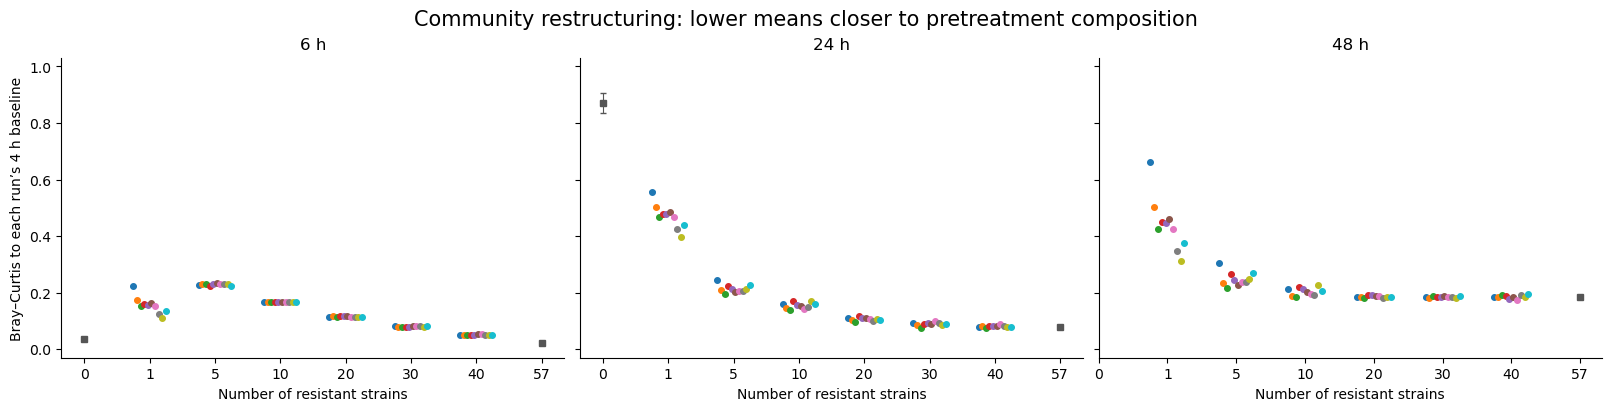

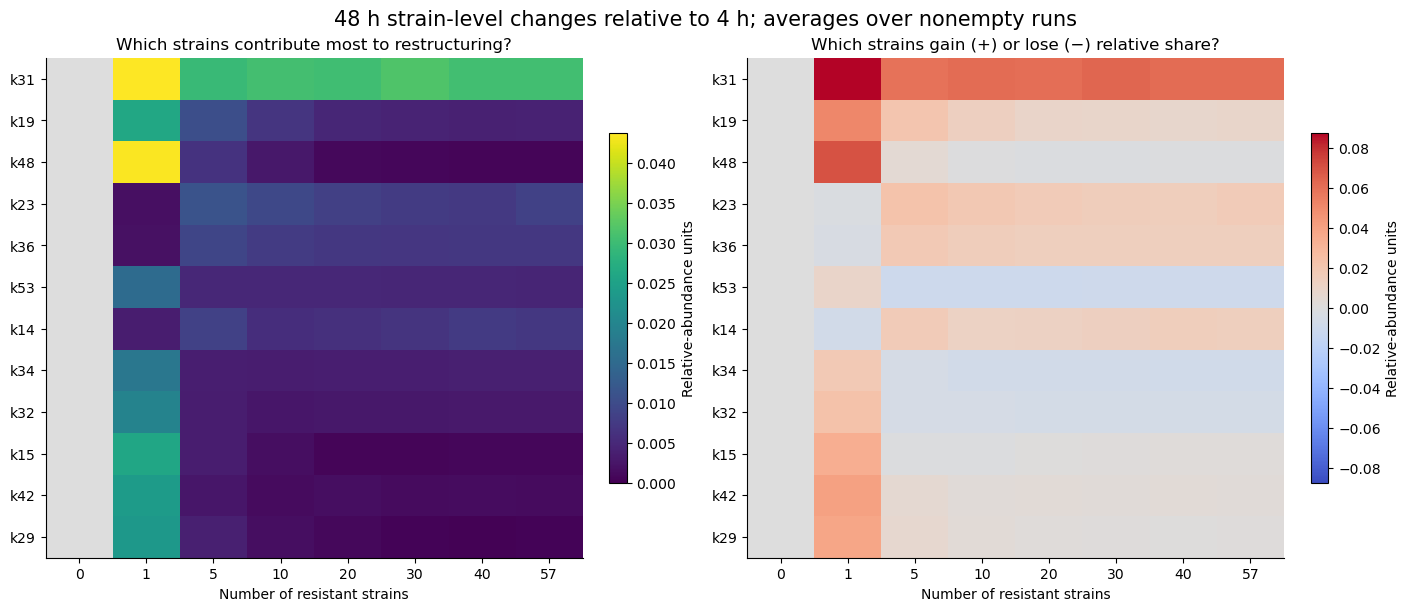

In [13]:
fig,axes=plt.subplots(1,3,figsize=(16,4),sharey=True,layout='constrained')
for ax,hour in zip(axes,[6.,24.,48.]):
    for d in assignment_stats[assignment_stats.hour.eq(hour)].itertuples():
        offset=0 if d.reference else (d.order_id-(N_ORDERS-1)/2)*.055
        ax.errorbar(COUNT_POS[d.n_resistant]+offset,d.bc_mean,yerr=d.bc_sd,fmt='s' if d.reference else 'o',
                    color='#555555' if d.reference else ORDER_COLORS[d.order_id],ms=4,capsize=2,lw=.8)
    ax.set(title=f'{hour:g} h',xlabel='Number of resistant strains',xticks=range(len(COUNTS)),xticklabels=COUNTS,ylim=(-.03,1.03))
axes[0].set_ylabel('Bray–Curtis to each run’s 4 h baseline')
fig.suptitle('Community restructuring: lower means closer to pretreatment composition',fontsize=15)
fig.savefig(FIGURES/'06_bray_curtis_by_count.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
leaders=species.groupby('strain').BC_contribution.mean().nlargest(12).index.tolist()
fig,axes=plt.subplots(1,2,figsize=(14,6),layout='constrained')
for ax,column,title,cmap in zip(axes,['BC_contribution','signed_relative_shift'],
 ['Which strains contribute most to restructuring?','Which strains gain (+) or lose (−) relative share?'],['viridis','coolwarm']):
    table=species.groupby(['strain','n_resistant'])[column].mean().unstack().reindex(index=leaders,columns=COUNTS)
    v=table.to_numpy();finite=v[np.isfinite(v)];limit=max(float(np.max(np.abs(finite))),1e-6)
    cm=plt.get_cmap(cmap).copy();cm.set_bad('#dddddd')
    image=ax.imshow(np.ma.masked_invalid(v),aspect='auto',cmap=cm,vmin=-limit if column=='signed_relative_shift' else 0,vmax=limit)
    ax.set_xticks(range(len(COUNTS)),COUNTS);ax.set_yticks(range(len(leaders)),leaders)
    ax.set(title=title,xlabel='Number of resistant strains')
    fig.colorbar(image,ax=ax,shrink=.7,label='Relative-abundance units')
fig.suptitle('48 h strain-level changes relative to 4 h; averages over nonempty runs',fontsize=15)
fig.savefig(FIGURES/'07_strain_restructuring.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
# Independent sum check: per-strain contributions recover community Bray–Curtis.
sums=species.groupby(['scenario','repeat']).BC_contribution.sum(min_count=1)
expected=samples[samples.treated&samples.hour.eq(48)].set_index(['scenario','repeat']).bray_curtis
np.testing.assert_allclose(sums.reindex(expected.index),expected,equal_nan=True,atol=1e-12)


## 13. Recovery probabilities and controls

We report extinction directly. For an illustrative **joint recovery criterion**, require at 48 h: at least 80% of the paired untreated biomass, at least 90% of paired untreated Shannon diversity, and Bray–Curtis ≤0.2 relative to that untreated community. These thresholds are explicit analysis choices, not biological constants; inspect the continuous outcomes too.

Each point below is the fraction of 10 event repeats meeting the criterion for one assignment. Ten repeats give a coarse estimate (steps of 0.1), so the per-assignment table includes Wilson 95% intervals for these event probabilities. The figure’s thin bars are those intervals, not diversity SD. Endpoint references have one assignment. We do not label assignment configurations as 100 independent cultures with identical recovery probability.

Untreated comparison helps distinguish antibiotic effects from natural competition, resource exhaustion and transfer. Arm repeats use independent noise; the same numeric repeat index is an explicit reporting pair.

Point colors use the same assignment-order colors as the earlier count plots; gray squares are shared reference assignments.

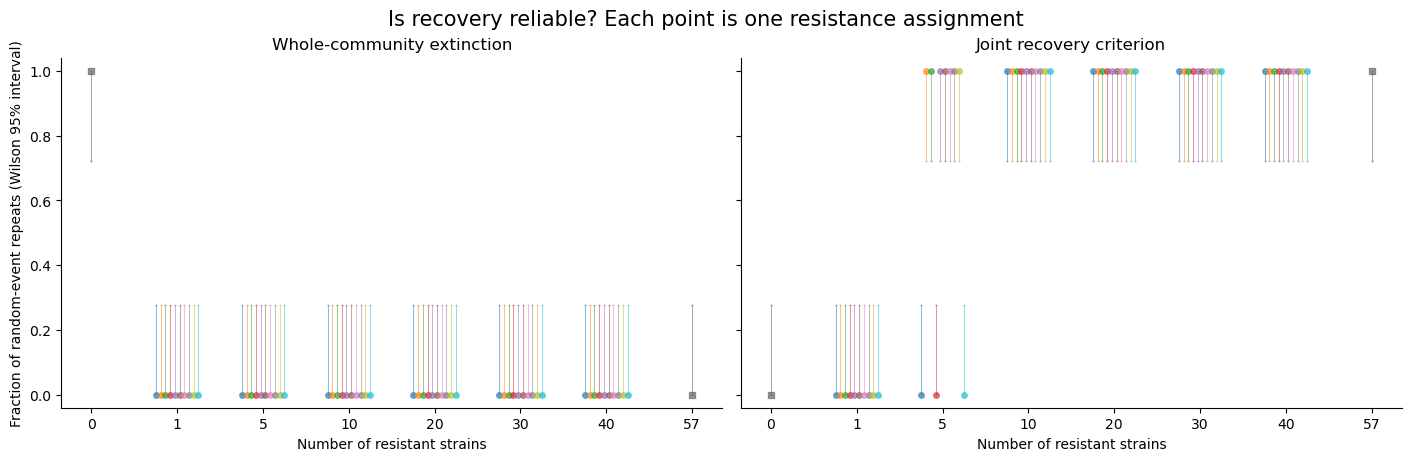

,event_repeats,extinct,recovered,mean_biomass_ratio,mean_shannon_ratio
n_resistant,,,,,
0,10,10,0,0.0000,NaN
1,100,0,0,1.0006,0.7467
5,100,0,70,1.0002,0.9730
10,100,0,100,1.0002,0.9973
20,100,0,100,1.0002,1.0072
30,100,0,100,1.0001,1.0095
40,100,0,100,1.0001,1.0068
57,10,0,10,1.0000,1.0000


In [14]:
endpoint=samples[samples.hour.eq(48)]
t=endpoint[endpoint.treated].set_index(['scenario','repeat'])
c=endpoint[~endpoint.treated].set_index(['scenario','repeat']).reindex(t.index)
comparison=t[['order_id','n_resistant','reference','extinct','biomass','shannon','bray_curtis']].copy()
comparison['biomass_ratio']=[safe_ratio(a,b) for a,b in zip(t.biomass,c.biomass)]
comparison['shannon_ratio']=[safe_ratio(a,b) for a,b in zip(t.shannon,c.shannon)]
comparison['BC_to_untreated']=[bray(at(STOCH[(s,r,True)],48),at(STOCH[(s,r,False)],48)) for s,r in comparison.index]
comparison['recovered']=(comparison.biomass_ratio>=.8)&(comparison.shannon_ratio>=.9)&(comparison.BC_to_untreated<=.2)&(~comparison.extinct)
comparison=comparison.reset_index();comparison.to_csv(OUT/'paired_recovery_comparisons.csv',index=False)

def wilson(success,n,z=1.96):
    p=success/n;den=1+z*z/n;center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half
probabilities=[]
for scenario,g in comparison.groupby('scenario'):
    row=g.iloc[0]
    for event in ['extinct','recovered']:
        successes=int(g[event].sum());low,high=wilson(successes,len(g))
        probabilities.append(dict(scenario=scenario,order_id=int(row.order_id),n_resistant=int(row.n_resistant),
            event=event,successes=successes,n_repeats=len(g),probability=successes/len(g),low=low,high=high))
probabilities=pd.DataFrame(probabilities);probabilities.to_csv(OUT/'event_probabilities_and_Wilson_intervals.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4.5),layout='constrained',sharey=True)
for ax,event in zip(axes,['extinct','recovered']):
    for r in probabilities[probabilities.event.eq(event)].itertuples():
        offset=0 if r.order_id<0 else (r.order_id-(N_ORDERS-1)/2)*.055
        ax.errorbar(COUNT_POS[r.n_resistant]+offset,r.probability,yerr=[[max(0,r.probability-r.low)],[max(0,r.high-r.probability)]],
                    fmt='s' if r.order_id<0 else 'o',color='#555555' if r.order_id<0 else ORDER_COLORS[r.order_id],
                    ms=4,lw=.6,capsize=1,alpha=.6)
    ax.set(title='Whole-community extinction' if event=='extinct' else 'Joint recovery criterion',xlabel='Number of resistant strains',xticks=range(len(COUNTS)),xticklabels=COUNTS,ylim=(-.04,1.04))
axes[0].set_ylabel('Fraction of random-event repeats (Wilson 95% interval)')
fig.suptitle('Is recovery reliable? Each point is one resistance assignment',fontsize=15)
fig.savefig(FIGURES/'08_recovery_and_extinction_probability.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
display(comparison.groupby('n_resistant').agg(event_repeats=('repeat','size'),
    extinct=('extinct','sum'),recovered=('recovered','sum'),mean_biomass_ratio=('biomass_ratio','mean'),
    mean_shannon_ratio=('shannon_ratio','mean')).round(4))


## 14. Baseline resistance versus later resilience

X = resistant-carrier biomass at 4 h, a **proxy** for β-lactamase capacity (the model does not track enzyme concentration). Because every carrier has the same capacity per OD, multiplying by `vmax` merely rescales x.

Each point summarizes one assignment/count configuration, not one species or one sampled time treated as an independent community. Y error bars are ±1 event SD. Correlations are computed on assignment means, excluding shared 0/57 endpoints, and are **descriptive**: nested counts share strains and time points are repeated observations. No independent-point p-values are claimed. A surviving-only diversity correlation does not account for extinction, so read it alongside the probability analysis.

A standard log axis cannot show zero; positive configurations are plotted on log x, while zero-carrier outcomes remain in the extinction and control tables. Do not interpret positive-range correlation as a monotonic relationship spanning the zero-carrier reference.

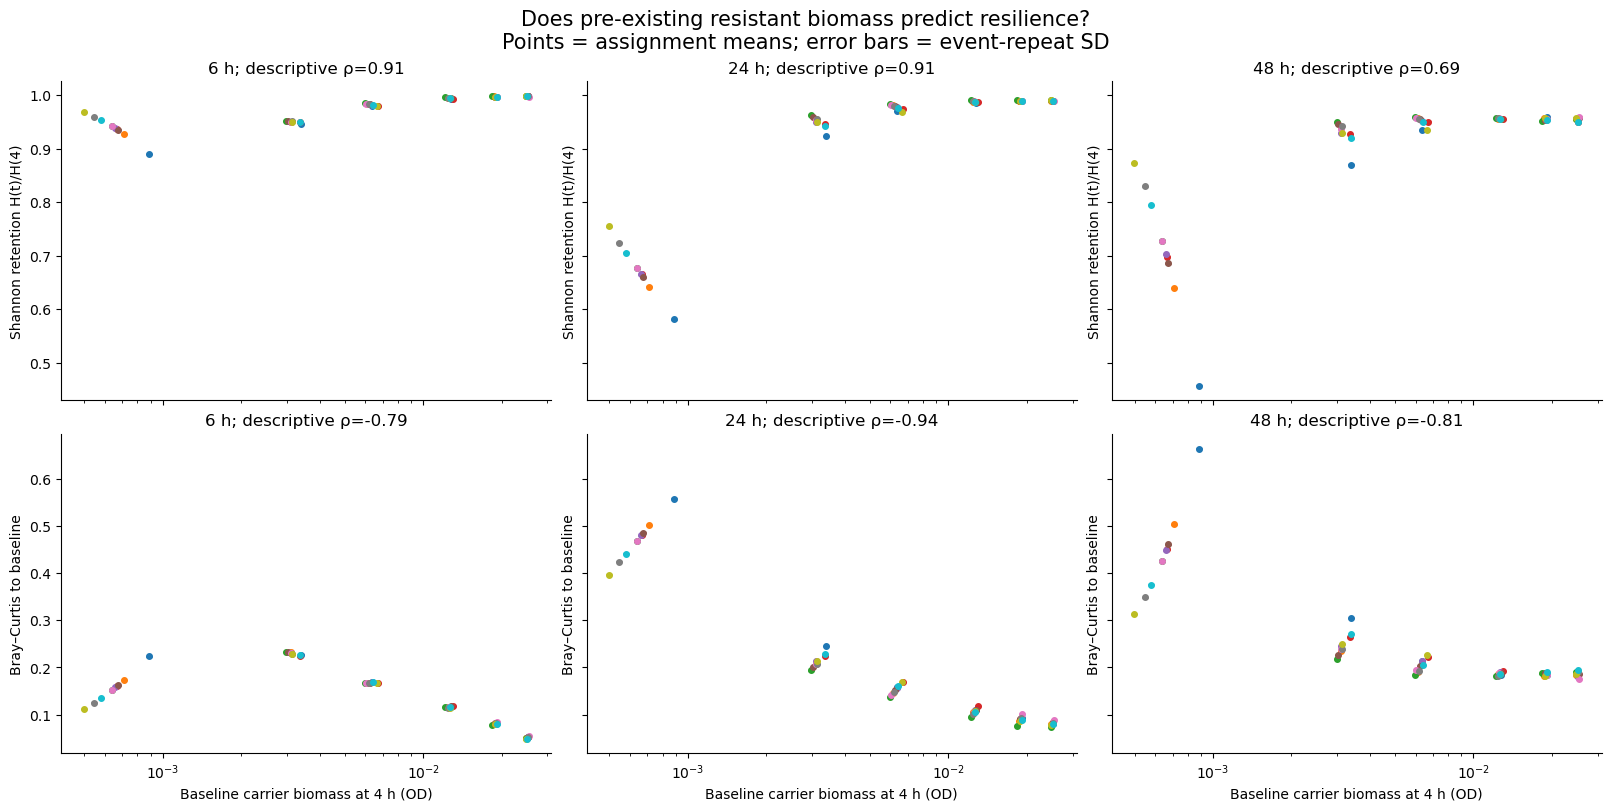

,hour,metric,spearman_rho,assignment_cells
0,6.0,retention_mean,0.914,60
1,6.0,bc_mean,-0.793,60
2,24.0,retention_mean,0.911,60
3,24.0,bc_mean,-0.937,60
4,48.0,retention_mean,0.691,60
5,48.0,bc_mean,-0.814,60


In [15]:
correlation_rows=[]
fig,axes=plt.subplots(2,3,figsize=(16,8),sharex=True,sharey='row',layout='constrained')
for col,hour in enumerate([6.,24.,48.]):
    g=assignment_stats[assignment_stats.hour.eq(hour)&~assignment_stats.reference]
    for row,(y,sd,title) in enumerate([('retention_mean','retention_sd','Shannon retention H(t)/H(4)'),('bc_mean','bc_sd','Bray–Curtis to baseline')]):
        ax=axes[row,col];valid=g[np.isfinite(g[y])&(g.carrier_baseline_mean>0)]
        for d in valid.itertuples():
            ax.errorbar(d.carrier_baseline_mean,getattr(d,y),yerr=getattr(d,sd),fmt='o',
                        color=ORDER_COLORS[d.order_id],ms=4,lw=.8,capsize=2)
        rho=float(spearmanr(valid.carrier_baseline_mean,valid[y]).statistic) if len(valid)>2 else np.nan
        correlation_rows.append(dict(hour=hour,metric=y,spearman_rho=rho,assignment_cells=len(valid)))
        ax.set_xscale('log');ax.set_title(f'{hour:g} h; descriptive ρ={rho:.2f}');ax.set_ylabel(title)
        if row==1:ax.set_xlabel('Baseline carrier biomass at 4 h (OD)')
fig.suptitle('Does pre-existing resistant biomass predict resilience?\nPoints = assignment means; error bars = event-repeat SD',fontsize=15)
fig.savefig(FIGURES/'09_baseline_resistance_correlations.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
correlations=pd.DataFrame(correlation_rows);display(correlations.round(3))
correlations.to_csv(OUT/'descriptive_correlations_on_assignment_means.csv',index=False)


## 15. What can we conclude, and what should we check next?

- **Better typical recovery?** Compare per-run means/medians, treated versus untreated and versus the original ODE.
- **More reliable recovery?** Compare the spread within an assignment and its recovery/extinction probability. Different assignments answer a separate identity question.
- **Restructuring?** Use Bray–Curtis plus signed strain shifts; Shannon alone cannot identify which strains changed.
- **Demographic noise or numerical bias?** Inspect the step-sensitivity and mean-step-versus-ODE tables. A systematic offset larger than event SD must not be attributed solely to stochasticity. Decrease the step limit to verify subtle conclusions.
- **Tiny stochastic spread?** At the original 10⁹ cells per OD, many populations are large enough that noise averages out. Report narrow uncertainty honestly. If exploring smaller cultures later, changing cell scale is a new experimental assumption and must be labeled separately.
- **Generalizability?** These results are conditional on one fixed intrinsic community, one dose, 10 assignment orders and 10 event repeats. More repeats improve probability estimates; more assignment orders test identity dependence; different trait seeds test different communities.

The model assumes carrier immunity and degradation-driven public protection. Favorable correlations are consequences consistent with those mechanisms, not independent proof that the same effects occur in patient microbiomes.

## Files and reproducibility

`design.csv`, `carrier_assignments.csv`, `fixed_traits.csv` record the community. `simulation_audit.csv` links every repeat to its stable event seed and compressed trajectory file. `individual_community_timecourses.csv.gz` stores per-run community trajectories; `individual_sampling_metrics.csv` stores sampled metrics; `strain_restructuring_48h.csv.gz` stores strain contributions. Assignment summaries, paired comparisons, event probabilities, descriptive correlations and numerical sensitivity tables have explicit filenames. `figures/` stores all scientific figures. `cache/` stores full strain trajectories, nutrients, antibiotic, transfer states and diagnostics.

Baseline comparison uses 4 h; sampled 24 h means before dilution. Full cache trajectories include the post-transfer duplicate at 24 h. Set `RECOMPUTE=True` only to force reruns; settings changes already create distinct cache keys. Increase `N_REPEATS` for better event-probability estimates. Save all cells in execution order; never merge event repeats into averaged profiles before computing diversity.


In [16]:
# Final validation: known event semantics, conservation, fixed state and sample accounting.
assert len(STOCH)==len(design)*N_REPEATS*2
assert not audit.duplicated(['scenario','repeat','treated']).any()
assert audit.mass_error.abs().max()<1e-6
for d in design.itertuples():
    reference_initial=STOCH[(d.scenario,0,True)]['N'][0]
    for treated in [False,True]:
        for rep in range(N_REPEATS):
            s=STOCH[(d.scenario,rep,treated)]
            np.testing.assert_array_equal(s['N'][0],reference_initial)
            np.testing.assert_array_equal(s['carrier'],MASKS[d.scenario])
            x=at(s,4.);assert x.sum()>=0
assert model.community is original_community
# Floor rule examples: 99 -> 0, 100 -> 1, 250 -> 2 cells.
np.testing.assert_array_equal(np.floor(np.array([99,100,250])/100),[0,1,2])
settings=dict(model_sha256=MODEL_SHA256,engine_sha256=ENGINE_SHA256,engine_version=ENGINE_VERSION,
    parameters=vars(BASE),deterministic_output_grid_h=.125,trait_seed=TRAIT_SEED,assignment_seed=ASSIGNMENT_SEED,event_seed=EVENT_SEED,
    n_orders=N_ORDERS,n_repeats=N_REPEATS,counts=COUNTS,max_step_h=DT_MAX,output_spacing_h=SAVE_DT,
    method='Approximate bounded birth/death tau-leap; original MM drug law; birth-coupled resource consumption; deterministic floor dilution.',
    recovery_thresholds=dict(biomass_ratio=.8,shannon_ratio=.9,BC_to_untreated=.2))
(OUT/'settings.json').write_text(json.dumps(settings,indent=2))
print('All final checks passed. Original biological parameters retained, including 10^9 cells per OD.')
print('Stochastic trajectories:',len(STOCH),'| deterministic controls:',len(ODE))
print('Resource-cap occurrences:',int(audit.resource_caps.sum()),'(recorded as a finite-step diagnostic).')
print('Outputs:',OUT.resolve())


All final checks passed. Original biological parameters retained, including 10^9 cells per OD.
Stochastic trajectories: 1240 | deterministic controls: 124
Resource-cap occurrences: 117 (recorded as a finite-step diagnostic).
Outputs: /Users/kylie/Desktop/Duke/Classes/BME574/project/BME574/updated_consumer_resource_model/test_resistance_distribution/stochastic_resistance_results
